# Final Project: Customer Churn Analysis for a Telecom Company
### Advanced Data Mining for Data-Driven Insights and Predictive Modeling

**Group AA:** Anushka Nanaware, Anusha Pittala

**Course:** MSCS-634-M50 - Advanced Big Data and Data Mining

**Assignment:** Residency Day 3 - Project Deliverable 4: Final Insights, Recommendations, and Presentation

## About This Notebook

This notebook brings together all four parts of our project in one place. We use one dataset, the **Telco Customer Churn** dataset (IBM sample data, 7,043 customers and 21 attributes), and ask one main question: **which customers are likely to leave the company, and what can the company do about it?**

| Part | What we did |
|---|---|
| **Part 1** | Data collection, cleaning and exploration (EDA) |
| **Part 2** | Feature engineering and regression models (Linear, Ridge, Lasso) with cross-validation |
| **Part 3** | Classification (Decision Tree and KNN with tuning), clustering (K-Means) and association rule mining (Apriori) |
| **Part 4** | Final insights, recommendations, a fairness check and ethical considerations |

**How to run:** open the notebook in Google Colab and choose Runtime, then Run all. The data loads directly from the IBM GitHub link, so no file upload is needed. The libraries used are pandas, numpy, matplotlib, seaborn, scikit-learn and mlxtend.

# Part 1: Data Collection, Cleaning, and Exploration

## 1.1 Dataset Selection and Description

**Dataset:** Telco Customer Churn (a sample customer dataset from IBM, widely used for churn analysis)

**What it contains:** 7,043 customers of a telecom company and 21 attributes. Each row is one customer. The attributes include:
- **Customer details:** gender, senior citizen, partner, dependents
- **Account details:** tenure (months with the company), contract type, paperless billing, payment method
- **Services:** phone service, multiple lines, internet service, online security, online backup, device protection, tech support, streaming TV, streaming movies
- **Charges:** monthly charges and total charges
- **Target:** Churn (whether the customer left the company)

**Why this dataset is appropriate:**
- It meets the requirements: 7,043 records (more than 500) and 21 attributes (more than 8 to 10).
- It is real-world customer behavior data, with a clear business problem: finding which customers are likely to leave and why.
- It has a mix of numeric attributes (tenure, monthly charges, total charges) and categorical attributes, so it works for every part of this project: regression (predicting charges), classification (predicting churn), clustering (customer segments), and association rule mining (which services are bought together).
- It needs real cleaning, including text numbers, blank values, and repeated category labels, which gives me meaningful preprocessing to practice.
- It also contains personal attributes such as gender and senior citizen status, which lets me think about fairness and ethics later in the project.

**Source:** IBM sample data repository on GitHub (also available on Kaggle as "Telco Customer Churn").

## 1.2 Loading and Initial Inspection
We load the data with Pandas and look at its size, column types, summary statistics and the values in each text column.

In [21]:
# Import the libraries we will use throughout this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Telco Customer Churn dataset directly from the IBM GitHub repository
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# How many rows (customers) and columns (attributes) do we have?
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (7043, 21)


In [22]:
# Show the first 5 rows to see what the data looks like
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
# info() shows each column's name, data type, and how many values are not empty
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [24]:
# describe() gives count, mean, spread, min, and max for numeric columns
df.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [25]:
# For each text column, show the different values it contains
# (skip customerID and TotalCharges, which have too many unique values)
text_cols = df.select_dtypes(include=["object", "string"]).columns.drop(["customerID", "TotalCharges"])

for col in text_cols:
    print(col, "->", df[col].unique().tolist())

gender -> ['Female', 'Male']
Partner -> ['Yes', 'No']
Dependents -> ['No', 'Yes']
PhoneService -> ['No', 'Yes']
MultipleLines -> ['No phone service', 'No', 'Yes']
InternetService -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity -> ['No', 'Yes', 'No internet service']
OnlineBackup -> ['Yes', 'No', 'No internet service']
DeviceProtection -> ['No', 'Yes', 'No internet service']
TechSupport -> ['No', 'Yes', 'No internet service']
StreamingTV -> ['No', 'Yes', 'No internet service']
StreamingMovies -> ['No', 'Yes', 'No internet service']
Contract -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling -> ['Yes', 'No']
PaymentMethod -> ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn -> ['No', 'Yes']


### Observations: Initial Inspection

- The dataset has **7,043 rows** (one per customer) and **21 columns**: 18 text columns, 2 integer columns (`SeniorCitizen`, `tenure`), and 1 decimal column (`MonthlyCharges`).
- `info()` shows no missing values at first glance, but `TotalCharges` is stored as **text** instead of a number. This is a data type problem that I need to fix before any analysis.
- `tenure` ranges from 0 to 72 months, with an average of about 32 months. A tenure of 0 means a customer who just joined and needs a closer look.
- MonthlyCharges ranges from about \$18 to \$119, with an average of about \$65.
- `SeniorCitizen` is stored as 0/1, while the other yes/no columns use "Yes"/"No". I may need to make these consistent.
- Several columns contain "No internet service" or "No phone service", which are really the same as "No" for the service in question. I will need to decide how to handle these repeated labels in the cleaning step.
- `Churn` has two values (Yes and No), so it is a good target for classification later.

## 1.3 Data Cleaning
In this step I check the data for missing values, duplicates, inconsistent labels and noisy values. I work on a copy called df_clean, so the original df stays untouched.

In [26]:
# The usual isnull() check can miss values that are stored as blank text.
print("Missing values (standard check):", df.isnull().sum().sum())

# TotalCharges looked like text earlier, so I look for blank strings
blank_mask = df["TotalCharges"].astype(str).str.strip() == ""
print("Blank TotalCharges entries:", blank_mask.sum())

# Look at those rows to understand why they are blank
df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Missing values (standard check): 0
Blank TotalCharges entries: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [27]:
# Make a copy so the raw data stays safe
df_clean = df.copy()

# Convert TotalCharges from text to numbers. Blank spaces become NaN.
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
print("Missing TotalCharges after conversion:", df_clean["TotalCharges"].isnull().sum())

# All 11 rows have tenure = 0, so these customers have not been billed yet.
# Their real total is 0, so I fill with 0 instead of deleting the rows.
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

print("Missing TotalCharges now:", df_clean["TotalCharges"].isnull().sum())
print("TotalCharges data type:", df_clean["TotalCharges"].dtype)

Missing TotalCharges after conversion: 11
Missing TotalCharges now: 0
TotalCharges data type: float64


In [28]:
# Check for duplicate rows and duplicate customer IDs
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())

# Check every text column for extra spaces at the start or end
text_cols = df_clean.select_dtypes(include=["object", "string"]).columns
space_issues = sum((df_clean[col] != df_clean[col].str.strip()).sum() for col in text_cols)
print("Text values with extra spaces:", space_issues)

Duplicate rows: 0
Duplicate customer IDs: 0
Text values with extra spaces: 0


In [29]:
# Check: do the extra labels match exactly with the internet/phone columns?
print("Rows saying 'No internet service' in OnlineSecurity:", (df_clean["OnlineSecurity"] == "No internet service").sum())
print("Customers with InternetService = No:", (df_clean["InternetService"] == "No").sum())
print("Rows saying 'No phone service' in MultipleLines:", (df_clean["MultipleLines"] == "No phone service").sum())
print("Customers with PhoneService = No:", (df_clean["PhoneService"] == "No").sum())

# The counts match, so these labels repeat information we already have.
# I change them to "No" so each service column has only Yes / No.
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
for col in service_cols:
    df_clean[col] = df_clean[col].replace({"No internet service": "No", "No phone service": "No"})

# SeniorCitizen is 0/1 while every other column uses Yes/No, so I make it match
df_clean["SeniorCitizen"] = df_clean["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Confirm the labels are now consistent
for col in service_cols + ["SeniorCitizen"]:
    print(col, "->", sorted(df_clean[col].unique().tolist()))

Rows saying 'No internet service' in OnlineSecurity: 1526
Customers with InternetService = No: 1526
Rows saying 'No phone service' in MultipleLines: 682
Customers with PhoneService = No: 682
MultipleLines -> ['No', 'Yes']
OnlineSecurity -> ['No', 'Yes']
OnlineBackup -> ['No', 'Yes']
DeviceProtection -> ['No', 'Yes']
TechSupport -> ['No', 'Yes']
StreamingTV -> ['No', 'Yes']
StreamingMovies -> ['No', 'Yes']
SeniorCitizen -> ['No', 'Yes']


In [30]:
# Noise check: TotalCharges should be close to tenure x MonthlyCharges
expected_total = df_clean["tenure"] * df_clean["MonthlyCharges"]
ratio = df_clean["TotalCharges"] / expected_total.replace(0, np.nan)   # skip tenure = 0 rows
print(ratio.describe().round(3))
print("Customers where TotalCharges differs from tenure x MonthlyCharges by more than 20%:", ((ratio < 0.8) | (ratio > 1.2)).sum())
print("Customers where it differs by more than 50%:", ((ratio < 0.5) | (ratio > 1.5)).sum())

# Outlier check with the IQR rule (values beyond 1.5 x IQR from the quartiles)
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    print(f"{col}: acceptable range {low:.1f} to {high:.1f}, outliers found = {n_out}")

count    7032.000
mean        1.000
std         0.051
min         0.689
25%         0.980
50%         1.000
75%         1.020
max         1.573
dtype: float64
Customers where TotalCharges differs from tenure x MonthlyCharges by more than 20%: 59
Customers where it differs by more than 50%: 2
tenure: acceptable range -60.0 to 124.0, outliers found = 0
MonthlyCharges: acceptable range -46.0 to 171.4, outliers found = 0
TotalCharges: acceptable range -4683.5 to 8868.7, outliers found = 0


In [31]:
# Before and after comparison
print("Original shape:", df.shape)
print("Cleaned shape :", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())
print(df_clean.dtypes.value_counts())

df_clean.head(3)

Original shape: (7043, 21)
Cleaned shape : (7043, 21)
Total missing values: 0
object     18
float64     2
int64       1
Name: count, dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


### Cleaning Summary

**1. Missing values.** The standard isnull() check found nothing, but TotalCharges had 11 blank text values. All 11 customers have tenure = 0 and have not churned, so they are brand-new customers who were not billed yet. I converted the column to numbers and filled these with 0. I kept the rows because deleting them would lose real customers for no good reason.

**2. Duplicates.** There were no duplicate rows and no duplicate customer IDs, so nothing was removed.

**3. Inconsistent data.** Six service columns used the label "No internet service" and MultipleLines used "No phone service". These match exactly the customers with no internet or phone, so they repeat information that is already in InternetService and PhoneService. I changed them to "No". I also changed SeniorCitizen from 0/1 to No/Yes so it matches the other columns.

**4. Noisy data.** TotalCharges should be roughly tenure x MonthlyCharges. The average ratio is 1.0, and only 59 customers differ by more than 20% (just 2 by more than 50%). This is normal noise from price changes over time, not data entry errors, so I kept these rows.

**5. Outliers.** The IQR rule found no outliers in tenure, MonthlyCharges or TotalCharges. The data looks clean and the spread of values is realistic.

## 1.4 Exploratory Data Analysis (EDA)
Here I use Seaborn and Matplotlib to look at (1) the target variable Churn, (2) the distributions of the numeric columns, (3) outliers, and (4) how the features relate to churn.

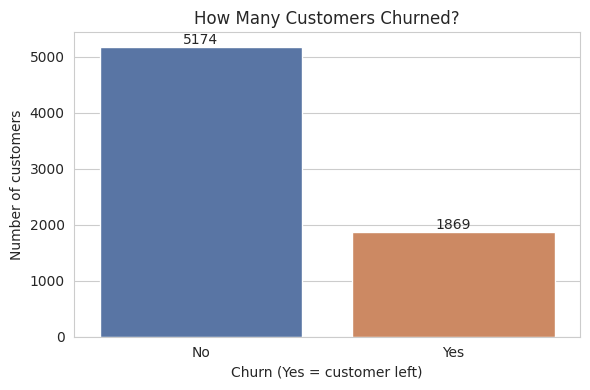

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


In [32]:
# Set a clean look for all charts
sns.set_style("whitegrid")

# Count how many customers churned and how many stayed
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_clean, x="Churn", hue="Churn",
              palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)

# Write the count on top of each bar
for bar in ax.patches:
    ax.annotate(f"{int(bar.get_height())}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")

ax.set_title("How Many Customers Churned?")
ax.set_xlabel("Churn (Yes = customer left)")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Same thing as percentages
print(df_clean["Churn"].value_counts(normalize=True).mul(100).round(1))

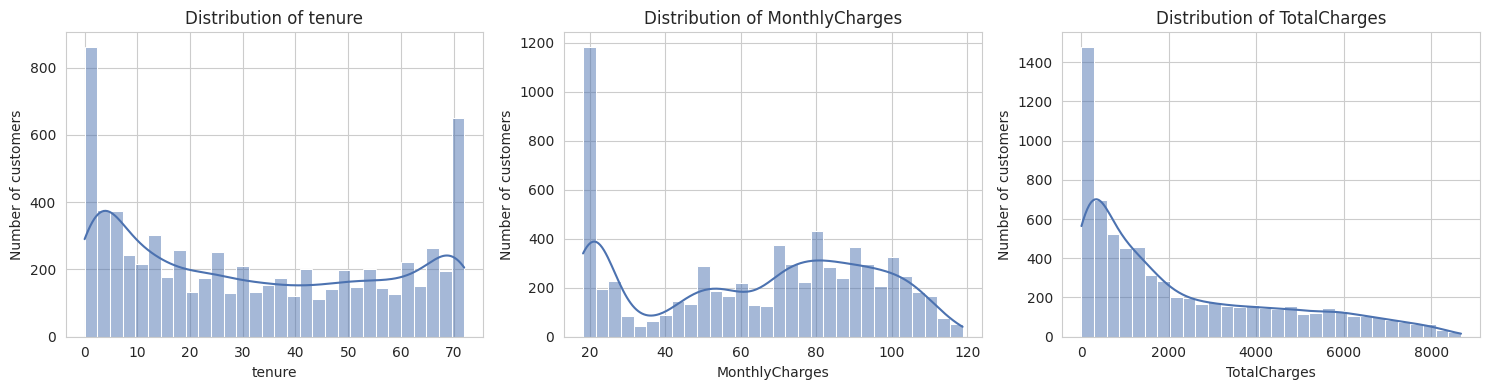

Skewness:
tenure            0.24
MonthlyCharges   -0.22
TotalCharges      0.96
dtype: float64


In [33]:
# Histograms show the shape of each numeric column
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df_clean[col], bins=30, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Skewness: 0 = symmetric, positive = long tail to the right
print("Skewness:")
print(df_clean[num_cols].skew().round(2))

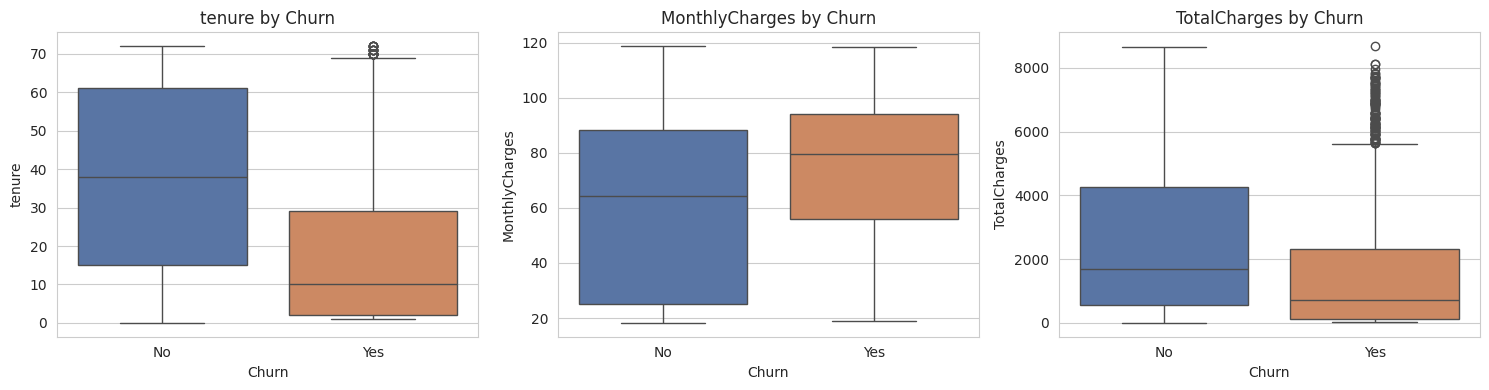

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0            64.4        1679.5
Yes      10.0            79.6         703.6


In [34]:
# Boxplots show the spread and any outliers (dots outside the whiskers).
# Splitting by Churn also shows how churners differ from loyal customers.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df_clean, x="Churn", y=col, hue="Churn",
                palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.show()

# Median values for each group
print(df_clean.groupby("Churn")[num_cols].median().round(1))

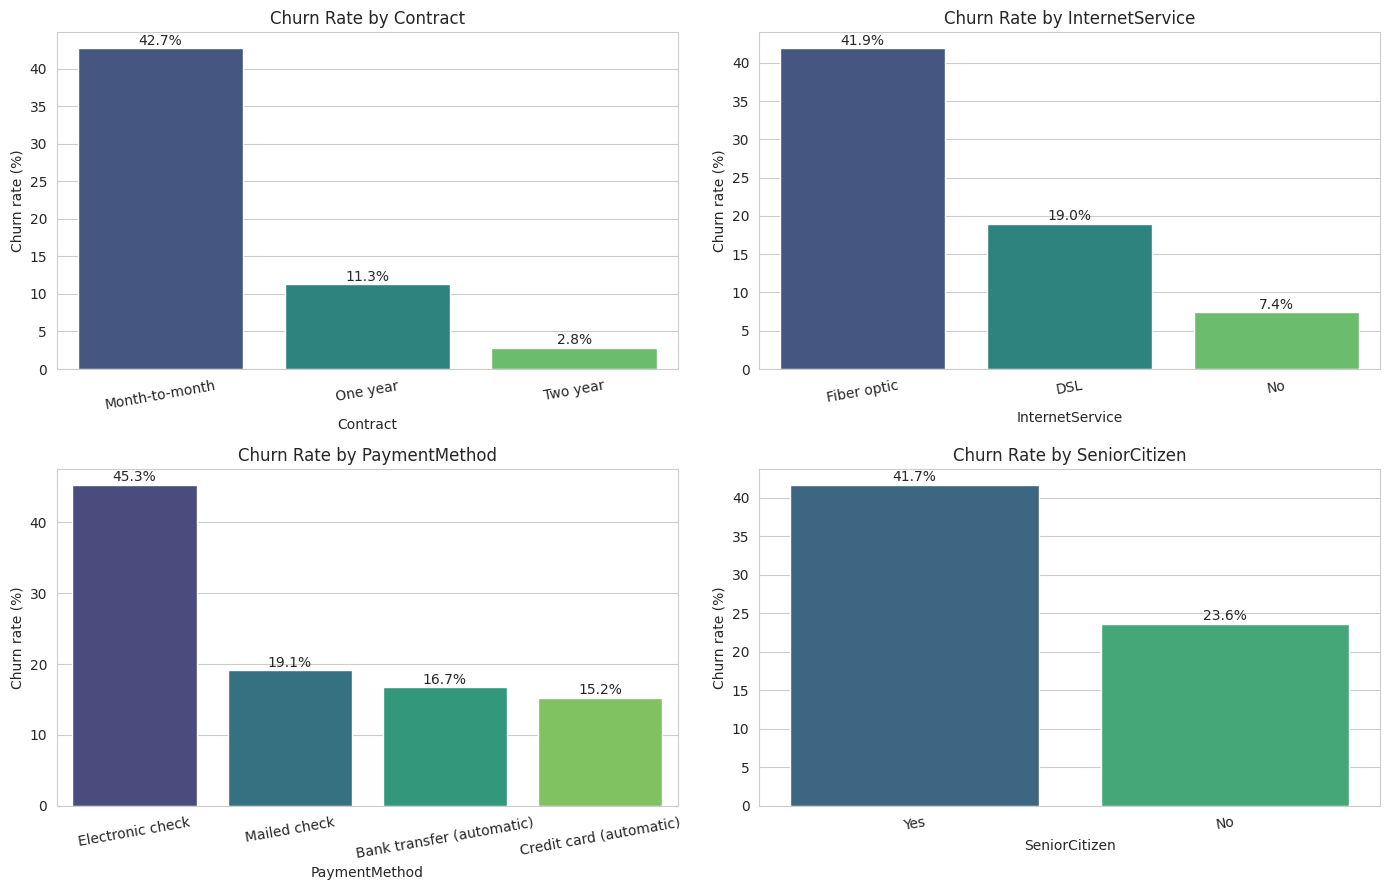

In [35]:
# For each category, calculate the % of customers who churned
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flatten(), ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen"]):
    rate = df_clean.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
    rate = rate.sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, hue=rate.index,
                palette="viridis", legend=False, ax=ax)
    # Write the percentage on top of each bar
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

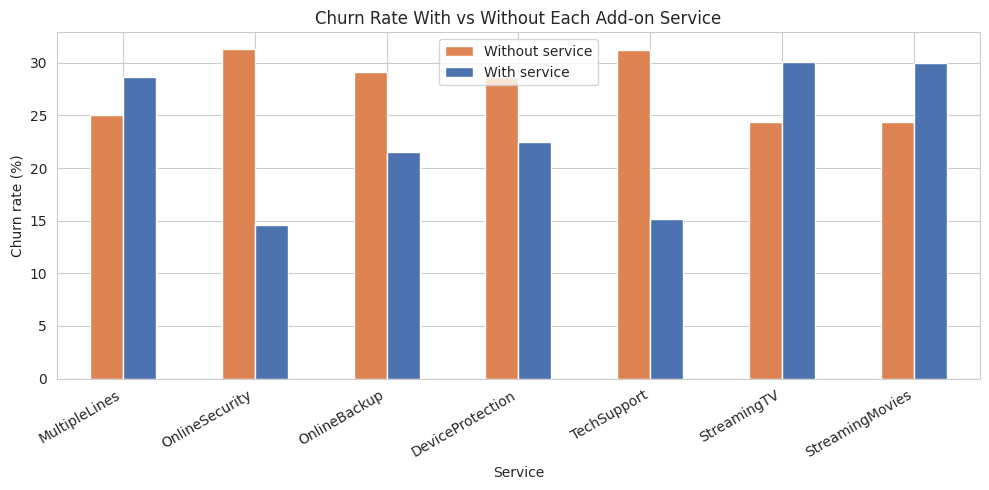

                  Without service  With service
Service                                        
MultipleLines                25.0          28.6
OnlineSecurity               31.3          14.6
OnlineBackup                 29.2          21.5
DeviceProtection             28.7          22.5
TechSupport                  31.2          15.2
StreamingTV                  24.3          30.1
StreamingMovies              24.4          29.9


In [36]:
# Compare churn rate for customers who have each add-on service vs those who do not
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]

rows = []
for col in service_cols:
    rate = df_clean.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
    rows.append({"Service": col, "Without service": rate["No"], "With service": rate["Yes"]})
service_rates = pd.DataFrame(rows).set_index("Service")

service_rates.plot(kind="bar", figsize=(10, 5), color=["#DD8452", "#4C72B0"])
plt.title("Churn Rate With vs Without Each Add-on Service")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print(service_rates.round(1))

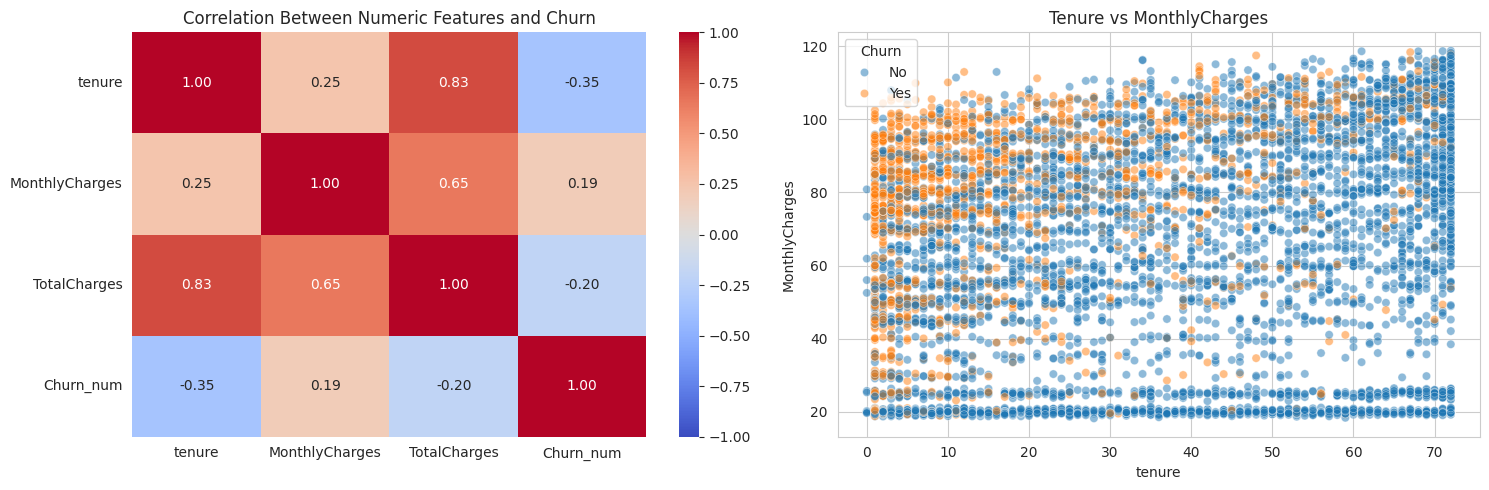

In [37]:
# Turn Churn into 0/1 so it can be included in the correlation
df_corr = df_clean.copy()
df_corr["Churn_num"] = (df_corr["Churn"] == "Yes").astype(int)
corr = df_corr[["tenure", "MonthlyCharges", "TotalCharges", "Churn_num"]].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: correlation heatmap
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation Between Numeric Features and Churn")

# Right: tenure vs MonthlyCharges, coloured by churn
sns.scatterplot(data=df_clean, x="tenure", y="MonthlyCharges", hue="Churn", alpha=0.5, ax=axes[1])
axes[1].set_title("Tenure vs MonthlyCharges")

plt.tight_layout()
plt.show()

### EDA Observations

**Target variable.** About 73.5% of customers stayed and 26.5% churned. The classes are imbalanced, so accuracy alone will be misleading later and I will also use precision, recall and F1.

**Distributions.** tenure has two peaks: many brand-new customers and many long-term customers. MonthlyCharges has a big group near the lowest price (customers with phone only) and then a wide spread. TotalCharges is skewed to the right (skewness 0.96) because it grows with tenure, so a log transform may help later.

**Outliers.** The IQR check on the full dataset found no outliers. In the boxplots split by Churn, a few dots appear only inside the churner group: 23 churners with tenure of 70 to 72 months and 109 with high TotalCharges. They look unusual only because most churners leave early. They are real long-term customers, not errors, so I kept them. Customers who churned have a much lower median tenure (10 vs 38 months) and a higher median MonthlyCharges (79.6 vs 64.4).

**Churn by category.** Month-to-month contracts churn at 42.7%, compared with 11.3% for one-year and 2.8% for two-year contracts. Fiber optic customers churn at 41.9%, compared with 19.0% for DSL. Electronic check users churn at 45.3%, far above the other payment methods (15% to 19%). Senior citizens churn at 41.7% vs 23.6% for others. Gender makes almost no difference (26.9% vs 26.2%).

**Add-on services.** Customers with OnlineSecurity (14.6%) or TechSupport (15.2%) churn about half as much as those without them (31.3% and 31.2%). Streaming services show a small opposite effect.

**Relationships between features.** TotalCharges is strongly related to tenure (0.83) and MonthlyCharges (0.65), which makes sense because it is roughly tenure x MonthlyCharges. This overlap (multicollinearity) matters for regression. Churn has a moderate negative link with tenure (-0.35) and a weak positive link with MonthlyCharges (0.19).

## 1.5 Key Insights and How They Guide Future Modeling

### Main insights
1. **Contract type is the strongest signal.** Month-to-month customers churn at 42.7%, while two-year customers churn at only 2.8%.
2. **New customers are the biggest risk.** Churners have a median tenure of 10 months vs 38 months for loyal customers, and churn has a negative link with tenure (-0.35).
3. **Price and service type matter.** Churners pay more each month (median 79.6 vs 64.4), and fiber optic customers churn at 41.9% vs 19.0% for DSL.
4. **Support services seem to keep customers.** Customers with OnlineSecurity or TechSupport churn at about 15%, half the rate of customers without them (about 31%).
5. **Payment method matters.** Electronic check users churn at 45.3%, far above automatic payment methods (15% to 17%).
6. **Gender is not useful.** Female and male customers churn at almost the same rate (26.9% vs 26.2%).

### How this guides the next deliverables
- **Classification (predicting Churn):** Churn is a clear Yes/No target. Because only 26.5% of customers churn, I will use stratified train/test splits and judge models with precision, recall and F1, not accuracy alone. I may also try class weights or resampling.
- **Regression:** TotalCharges is almost tenure x MonthlyCharges, so predicting it would be too easy. MonthlyCharges is a better target, using the contract, services and tenure as predictors. Since tenure, MonthlyCharges and TotalCharges are highly correlated (up to 0.83), I will watch for multicollinearity and may use Ridge or Lasso.
- **Feature engineering ideas:** group tenure into bands (0-12, 13-24, 25-48, 49-72 months), count how many add-on services each customer has, flag customers with no support services, and log-transform TotalCharges because it is right-skewed.
- **Preprocessing:** one-hot encode the text columns (Contract, InternetService, PaymentMethod and the Yes/No columns), scale numeric features for distance-based methods such as KNN and clustering, and drop customerID because it is only an identifier.
- **Clustering:** tenure, MonthlyCharges and the contract type can reveal customer groups, such as new high-paying fiber customers vs long-term low-cost customers.
- **Association rules:** the Yes/No service columns work as items, so I can look for rules such as OnlineSecurity and TechSupport appearing together, and link them to churn.
- **Ethics and fairness:** gender and SeniorCitizen are personal attributes. Gender shows no real signal, so I will likely leave it out. Senior citizens churn more, but using age to treat customers differently could be unfair, so I will check model results across these groups before drawing conclusions.

# Part 2: Feature Engineering and Regression Modeling

## 2.1 Goal and Target Variable

In this deliverable I build regression models on the same Telco Customer Churn dataset from Deliverable 1. The goal is to predict **TotalCharges**, the total amount a customer has paid, using the customer's account details and services. I also use feature engineering to improve the models, then compare them with R-squared, MSE, RMSE and cross-validation.

**Why TotalCharges?** In Deliverable 1, I planned to use MonthlyCharges as the target. When I tested it, plain features already predicted it almost perfectly because the monthly price is just the sum of the service prices. That leaves nothing to improve or compare. TotalCharges is harder to predict with basic features, so feature engineering and model choice can make a real difference.

count    7043.00
mean     2279.73
std      2266.79
min         0.00
25%       398.55
50%      1394.55
75%      3786.60
max      8684.80
Name: TotalCharges, dtype: float64


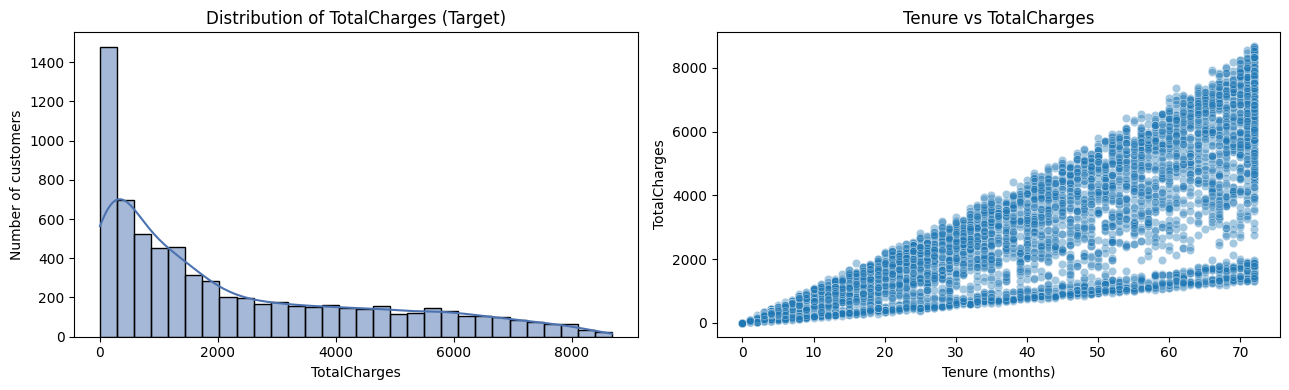

Correlation with tenure: 0.83
Correlation with MonthlyCharges: 0.65


In [3]:
# Look at the target variable: TotalCharges
print(df_clean["TotalCharges"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: how the target values are spread out
sns.histplot(df_clean["TotalCharges"], bins=30, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of TotalCharges (Target)")
axes[0].set_xlabel("TotalCharges")
axes[0].set_ylabel("Number of customers")

# Right: how the target relates to tenure
sns.scatterplot(data=df_clean, x="tenure", y="TotalCharges", alpha=0.4, ax=axes[1])
axes[1].set_title("Tenure vs TotalCharges")
axes[1].set_xlabel("Tenure (months)")
axes[1].set_ylabel("TotalCharges")

plt.tight_layout()
plt.show()

# How strongly are the target and the main numeric features related?
print("Correlation with tenure:", round(df_clean["TotalCharges"].corr(df_clean["tenure"]), 2))
print("Correlation with MonthlyCharges:", round(df_clean["TotalCharges"].corr(df_clean["MonthlyCharges"]), 2))

## 2.2 Baseline Features and Train/Test Split

Before any feature engineering, I build a **baseline** feature table with the original columns only. The baseline gives me something fair to compare against later.

- **Target (y):** TotalCharges.
- **Features (X):** all other columns except customerID, which is only an identifier. TotalCharges is the target, so it is not used as a feature.
- **Encoding:** the models only understand numbers, so I turn each text column into 0/1 columns (one-hot encoding). I drop the first category of each column to avoid duplicated information.
- **Split:** 80% of the customers are used for training and 20% are kept aside for testing. I set random_state so the split is the same every time.
- **Scaling:** I will scale the features inside the model pipelines in Step 4. This way the test data never influences the scaling.

In [4]:
# The target we want to predict
y = df_clean["TotalCharges"]

# Baseline features: all columns except the ID and the target
X_base = df_clean.drop(columns=["customerID", "TotalCharges"])

# One-hot encode the text columns (turn each category into a 0/1 column).
# drop_first=True removes one category per column to avoid duplicated information.
X_base = pd.get_dummies(X_base, drop_first=True).astype(float)

print("Baseline feature table shape:", X_base.shape)
print("Number of features:", X_base.shape[1])
print(X_base.columns.tolist())

Baseline feature table shape: (7043, 23)
Number of features: 23
['tenure', 'MonthlyCharges', 'gender_Male', 'SeniorCitizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'Churn_Yes']


In [5]:
from sklearn.model_selection import train_test_split

# Keep 80% of the customers for training and 20% for testing.
# random_state=42 makes the split the same every time we run the notebook.
X_train, X_test, y_train, y_test = train_test_split(X_base, y, test_size=0.2, random_state=42)

print("Training rows:", X_train.shape[0])
print("Test rows    :", X_test.shape[0])

# Check that both sets have a similar average target value
print("Mean TotalCharges - training:", round(y_train.mean(), 2))
print("Mean TotalCharges - test    :", round(y_test.mean(), 2))

# All features should now be numbers
print(X_base.dtypes.value_counts())

Training rows: 5634
Test rows    : 1409
Mean TotalCharges - training: 2287.09
Mean TotalCharges - test    : 2250.33
float64    23
Name: count, dtype: int64


## 2.3 Feature Engineering

Feature engineering means creating new columns from the existing ones so the models can learn more. I use ideas from the EDA in Deliverable 1:

- **expected_total** = tenure x MonthlyCharges. A customer's total bill should be close to what they pay each month times how many months they stayed. This is the strongest idea, because the relationship between these three columns is multiplication, and a straight-line model cannot create a multiplication by itself.
- **num_addons**: how many of the 7 add-on services the customer has. More services usually means a higher bill.
- **has_support**: 1 if the customer has OnlineSecurity or TechSupport. In the EDA these customers churned about half as much, so they tend to stay longer and pay more in total.
- **contract_months**: the contract length as a number (Month-to-month = 1, One year = 12, Two year = 24). This turns the contract type into a number that shows its order.
- **tenure_band**: groups of tenure (0-12, 13-24, 25-48, 49-72 months). This lets the model treat new and long-term customers differently.

In [6]:
# Work on a copy so df_clean stays unchanged
df_fe = df_clean.copy()

# 1. Expected total = months with the company x monthly price
df_fe["expected_total"] = df_fe["tenure"] * df_fe["MonthlyCharges"]

# 2. How many of the 7 add-on services does the customer have?
df_fe["num_addons"] = (df_fe[service_cols] == "Yes").sum(axis=1)

# 3. Does the customer have a support service (OnlineSecurity or TechSupport)? 1 = yes, 0 = no
df_fe["has_support"] = ((df_fe["OnlineSecurity"] == "Yes") | (df_fe["TechSupport"] == "Yes")).astype(int)

# 4. Contract length as a number of months
contract_months = {"Month-to-month": 1, "One year": 12, "Two year": 24}
df_fe["contract_months"] = df_fe["Contract"].map(contract_months)

# 5. Group tenure into bands (new, growing, established, long-term customers)
df_fe["tenure_band"] = pd.cut(df_fe["tenure"], bins=[-1, 12, 24, 48, 72],
                              labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)

# Look at the new columns
new_cols = ["expected_total", "num_addons", "has_support", "contract_months", "tenure_band"]
df_fe[["tenure", "MonthlyCharges"] + new_cols].head()

,tenure,MonthlyCharges,expected_total,num_addons,has_support,contract_months,tenure_band
0,1,29.85,29.85,1,0,1,0-12
1,34,56.95,1936.30,2,1,12,25-48
2,2,53.85,107.70,2,1,1,0-12
3,45,42.30,1903.50,3,1,12,25-48
4,2,70.70,141.40,0,0,1,0-12


expected_total     0.9996
num_addons         0.7859
has_support        0.4820
contract_months    0.4449
Name: TotalCharges, dtype: float64


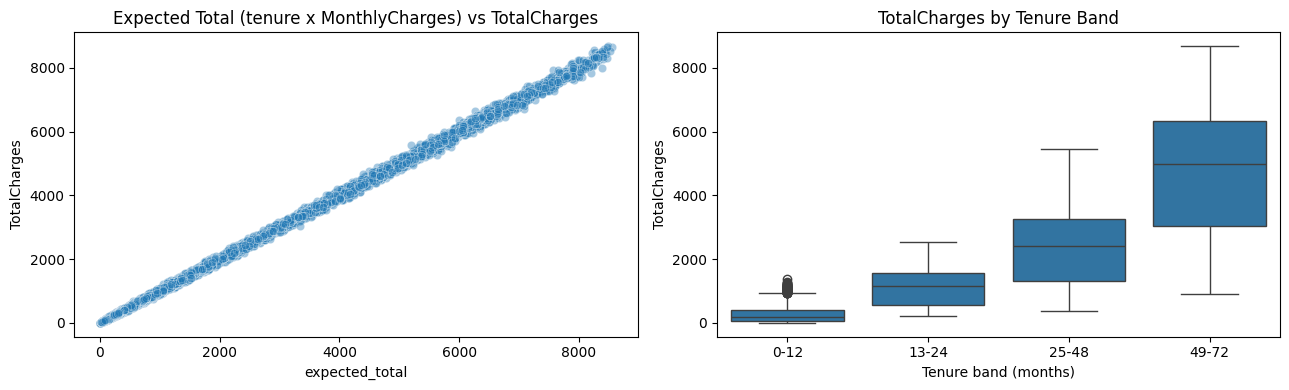

In [7]:
# How strongly is each new numeric feature related to the target?
corr_check = df_fe[["TotalCharges", "expected_total", "num_addons", "has_support", "contract_months"]].corr()["TotalCharges"]
print(corr_check.drop("TotalCharges").round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: expected_total vs the target
sns.scatterplot(data=df_fe, x="expected_total", y="TotalCharges", alpha=0.4, ax=axes[0])
axes[0].set_title("Expected Total (tenure x MonthlyCharges) vs TotalCharges")
axes[0].set_xlabel("expected_total")
axes[0].set_ylabel("TotalCharges")

# Right: TotalCharges for each tenure band
sns.boxplot(data=df_fe, x="tenure_band", y="TotalCharges",
            order=["0-12", "13-24", "25-48", "49-72"], ax=axes[1])
axes[1].set_title("TotalCharges by Tenure Band")
axes[1].set_xlabel("Tenure band (months)")
axes[1].set_ylabel("TotalCharges")

plt.tight_layout()
plt.show()

In [8]:
# Build the full engineered feature table: drop the ID and the target, then one-hot encode
X_eng = df_fe.drop(columns=["customerID", "TotalCharges"])
X_eng = pd.get_dummies(X_eng, drop_first=True).astype(float)

# Use exactly the same customers for training and testing as the baseline split,
# so the comparison between baseline and engineered features is fair
X_train_eng = X_eng.loc[X_train.index]
X_test_eng = X_eng.loc[X_test.index]

print("Baseline features  :", X_base.shape[1])
print("Engineered features:", X_eng.shape[1])
print("Training rows:", X_train_eng.shape[0], " Test rows:", X_test_eng.shape[0])
print("New columns:", sorted(set(X_eng.columns) - set(X_base.columns)))

Baseline features  : 23
Engineered features: 30
Training rows: 5634  Test rows: 1409
New columns: ['contract_months', 'expected_total', 'has_support', 'num_addons', 'tenure_band_13-24', 'tenure_band_25-48', 'tenure_band_49-72']


## 2.4 Building the Regression Models

I build three regression models and train each one on three different feature sets. This gives 9 trained models, so I can see both which model works best and which features help the most.

**Models:**
- **Linear Regression:** fits a straight-line formula using all the features. It is the simple starting point.
- **Ridge Regression:** like Linear Regression, but it shrinks large coefficients (weights) to stop the model from depending too much on any one feature. It helps when features are correlated, such as tenure, MonthlyCharges and TotalCharges.
- **Lasso Regression:** like Ridge, but it can shrink some coefficients all the way to zero, so it also picks the most useful features.

**Feature sets:**
1. **Baseline:** the original columns only.
2. **Engineered (no expected_total):** the baseline plus the new features, but without expected_total.
3. **Engineered (full):** all new features, including expected_total.

Ridge and Lasso both need a setting called alpha, which controls how strongly they shrink the coefficients. I let cross-validation choose the best alpha using the training data only. All models use a StandardScaler inside a pipeline, which puts the features on the same scale and keeps the test data out of the scaling.

In [9]:
# Put the three versions of the data in one place.
# Each entry is (training features, test features).
feature_sets = {
    "Baseline": (X_train, X_test),
    "Engineered (no expected_total)": (X_train_eng.drop(columns=["expected_total"]),
                                       X_test_eng.drop(columns=["expected_total"])),
    "Engineered (full)": (X_train_eng, X_test_eng),
}

for name, (Xtr, Xte) in feature_sets.items():
    print(f"{name:32s} features: {Xtr.shape[1]}  train rows: {Xtr.shape[0]}  test rows: {Xte.shape[0]}")

Baseline                         features: 23  train rows: 5634  test rows: 1409
Engineered (no expected_total)   features: 29  train rows: 5634  test rows: 1409
Engineered (full)                features: 30  train rows: 5634  test rows: 1409


In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV

def build_models():
    """Create a fresh copy of the three models. Each one scales the features first."""
    return {
        # Plain linear regression: no shrinking
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        # Ridge: shrinks coefficients. RidgeCV tries 30 alpha values and keeps the best one.
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
        # Lasso: can shrink some coefficients to exactly zero. LassoCV picks alpha with 5-fold CV.
        "Lasso": make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=20000, random_state=42)),
    }

# Train every model on every feature set (3 feature sets x 3 models = 9 models)
fitted = {}
for set_name, (Xtr, Xte) in feature_sets.items():
    models = build_models()
    for model_name, model in models.items():
        model.fit(Xtr, y_train)                 # learn from the training data only
        fitted[(set_name, model_name)] = model  # save the trained model

print("Models trained:", len(fitted))

Models trained: 9


In [11]:
# Show the alpha that cross-validation chose, and how many features Lasso removed
for set_name in feature_sets:
    ridge_alpha = fitted[(set_name, "Ridge")].named_steps["ridgecv"].alpha_
    lasso_model = fitted[(set_name, "Lasso")].named_steps["lassocv"]
    n_zero = int((lasso_model.coef_ == 0).sum())
    print(f"{set_name:32s} Ridge alpha: {ridge_alpha:8.2f} | Lasso alpha: {lasso_model.alpha_:8.3f} | "
          f"Lasso removed {n_zero} of {len(lasso_model.coef_)} features")

Baseline                         Ridge alpha:     1.74 | Lasso alpha:    2.477 | Lasso removed 0 of 23 features
Engineered (no expected_total)   Ridge alpha:     1.17 | Lasso alpha:    1.874 | Lasso removed 5 of 29 features
Engineered (full)                Ridge alpha:     0.11 | Lasso alpha:    2.262 | Lasso removed 28 of 30 features


## 2.5 Model Evaluation

I evaluate each of the 9 models in two ways.

**1. On the test set** (the 20% of customers the model never saw during training):
- **R-squared (R2):** how much of the ups and downs in TotalCharges the model explains. 1.0 is perfect, and 0 means no better than guessing the average.
- **MSE (Mean Squared Error):** the average of the squared prediction errors. Bigger mistakes are punished more.
- **RMSE (Root Mean Squared Error):** the square root of MSE. It is in the same units as TotalCharges, so it tells us roughly how far off a typical prediction is. Lower is better.

**2. With 5-fold cross-validation** on the training data. The training data is split into 5 parts. The model is trained on 4 parts and tested on the 5th, and this is repeated 5 times so every part is used for testing once. If the cross-validation scores are close to the test scores, and do not jump around much, the model should work well on new customers too.

In [12]:
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import KFold, cross_validate

# 5-fold cross-validation setup. Shuffle the rows first so each fold is a fair mix.
kf = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for set_name, (Xtr, Xte) in feature_sets.items():
    for model_name in ["Linear Regression", "Ridge", "Lasso"]:
        model = fitted[(set_name, model_name)]

        # --- Test set scores: predict the customers the model has never seen ---
        pred = model.predict(Xte)
        mse = mean_squared_error(y_test, pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, pred)

        # --- Cross-validation scores on the training data ---
        # (cross_validate makes a fresh copy of the model for each fold)
        cv = cross_validate(model, Xtr, y_train, cv=kf,
                            scoring=("r2", "neg_root_mean_squared_error"))

        rows.append({
            "Feature Set": set_name,
            "Model": model_name,
            "Test R2": r2,
            "Test MSE": mse,
            "Test RMSE": rmse,
            "CV R2 (mean)": cv["test_r2"].mean(),
            "CV R2 (std)": cv["test_r2"].std(),
            "CV RMSE (mean)": -cv["test_neg_root_mean_squared_error"].mean(),
        })

# Put all the scores in one table
results = pd.DataFrame(rows)
results.round(4)

,Feature Set,Model,Test R2,Test MSE,Test RMSE,CV R2 (mean),CV R2 (std),CV RMSE (mean)
0,Baseline,Linear Regression,0.9059,489578.9309,699.6992,0.9075,0.0021,688.2127
1,Baseline,Ridge,0.9058,489992.0319,699.9943,0.9074,0.0021,688.2598
2,Baseline,Lasso,0.9058,490163.1193,700.1165,0.9075,0.0022,688.1073
3,Engineered (no expected_total),Linear Regression,0.9090,473595.9904,688.1831,0.9119,0.0024,671.5869
4,Engineered (no expected_total),Ridge,0.9089,473978.5287,688.4610,0.9119,0.0024,671.6056
5,Engineered (no expected_total),Lasso,0.9085,476153.8538,690.0390,0.9118,0.0025,671.8982
6,Engineered (full),Linear Regression,0.9991,4674.0320,68.3669,0.9991,0.0000,67.1465
7,Engineered (full),Ridge,0.9991,4673.9907,68.3666,0.9991,0.0000,67.1463
8,Engineered (full),Lasso,0.9991,4625.0597,68.0078,0.9991,0.0001,67.0055


In [13]:
# Rank all 9 models from the lowest to the highest test RMSE (lower = better)
ranked = results.sort_values("Test RMSE").reset_index(drop=True)
print(ranked[["Feature Set", "Model", "Test R2", "Test RMSE", "CV R2 (mean)", "CV RMSE (mean)"]].round(4).to_string())

# Show the best model
best = ranked.iloc[0]
print("\nBest model:", best["Model"], "with", best["Feature Set"])
print("Test R2:", round(best["Test R2"], 4), "| Test RMSE:", round(best["Test RMSE"], 2))

# For context: how big is a typical TotalCharges value?
print("\nAverage TotalCharges in the test set:", round(y_test.mean(), 1))
print("Spread (std) of TotalCharges in the test set:", round(y_test.std(), 1))

                      Feature Set              Model  Test R2  Test RMSE  CV R2 (mean)  CV RMSE (mean)
0               Engineered (full)              Lasso   0.9991    68.0078        0.9991         67.0055
1               Engineered (full)              Ridge   0.9991    68.3666        0.9991         67.1463
2               Engineered (full)  Linear Regression   0.9991    68.3669        0.9991         67.1465
3  Engineered (no expected_total)  Linear Regression   0.9090   688.1831        0.9119        671.5869
4  Engineered (no expected_total)              Ridge   0.9089   688.4610        0.9119        671.6056
5  Engineered (no expected_total)              Lasso   0.9085   690.0390        0.9118        671.8982
6                        Baseline  Linear Regression   0.9059   699.6992        0.9075        688.2127
7                        Baseline              Ridge   0.9058   699.9943        0.9074        688.2598
8                        Baseline              Lasso   0.9058   700.1165 

## 2.6 Visualizing Model Performance

These charts compare the models in different ways: the error and cross-validation score of all 9 models, how close the predictions are to the real values, and which features the Lasso model found most useful.

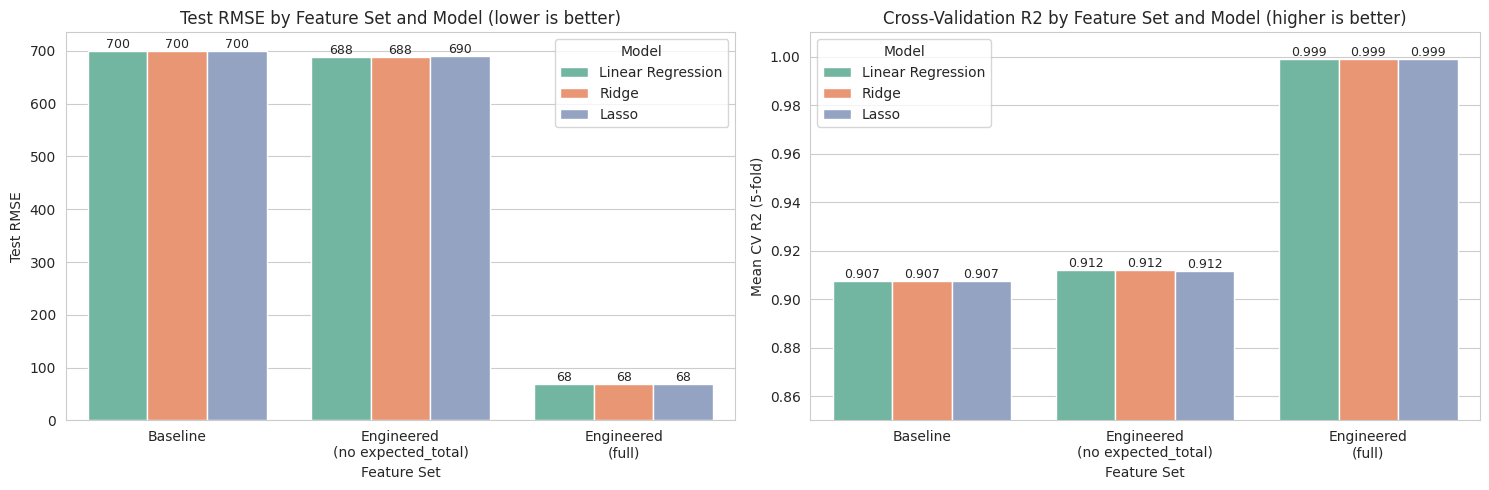

In [14]:
sns.set_style("whitegrid")

# Use shorter names for the feature sets so the chart labels fit
plot_data = results.copy()
plot_data["Feature Set"] = plot_data["Feature Set"].replace({
    "Engineered (no expected_total)": "Engineered\n(no expected_total)",
    "Engineered (full)": "Engineered\n(full)"})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: test RMSE (lower is better)
sns.barplot(data=plot_data, x="Feature Set", y="Test RMSE", hue="Model", palette="Set2", ax=axes[0])
axes[0].set_title("Test RMSE by Feature Set and Model (lower is better)")
axes[0].set_ylabel("Test RMSE")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", fontsize=9)   # write the value on each bar

# Right: cross-validation R2 (higher is better)
sns.barplot(data=plot_data, x="Feature Set", y="CV R2 (mean)", hue="Model", palette="Set2", ax=axes[1])
axes[1].set_title("Cross-Validation R2 by Feature Set and Model (higher is better)")
axes[1].set_ylabel("Mean CV R2 (5-fold)")
axes[1].set_ylim(0.85, 1.01)   # zoom in, because all scores are high
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.3f", fontsize=9)

plt.tight_layout()
plt.show()

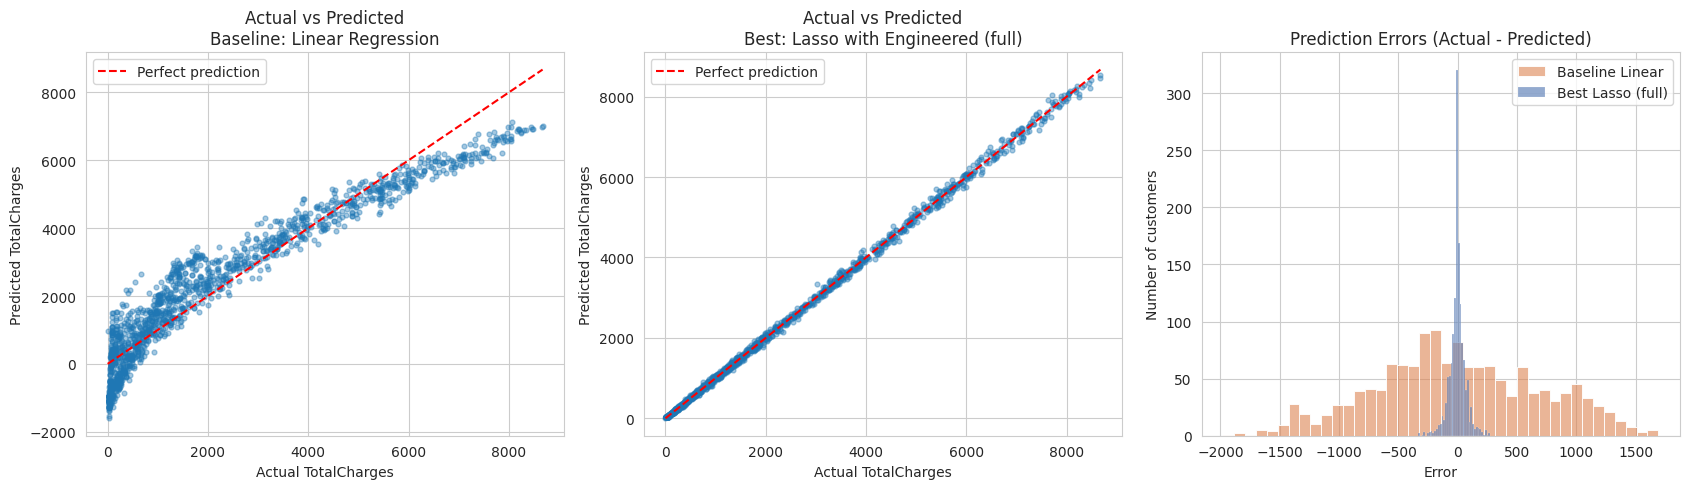

In [15]:
# Predictions from the baseline model and from the best model
best_pred = fitted[("Engineered (full)", "Lasso")].predict(feature_sets["Engineered (full)"][1])
base_pred = fitted[("Baseline", "Linear Regression")].predict(feature_sets["Baseline"][1])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
lims = [0, y_test.max()]   # range for the "perfect prediction" line

# Left and middle: each dot is one test customer. Dots on the red line are perfect predictions.
for ax, pred, title in [(axes[0], base_pred, "Baseline: Linear Regression"),
                        (axes[1], best_pred, "Best: Lasso with Engineered (full)")]:
    ax.scatter(y_test, pred, alpha=0.4, s=12)
    ax.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")
    ax.set_title(f"Actual vs Predicted\n{title}")
    ax.set_xlabel("Actual TotalCharges")
    ax.set_ylabel("Predicted TotalCharges")
    ax.legend()

# Right: how big the prediction errors are for the two models
sns.histplot(y_test - base_pred, bins=40, color="#DD8452", label="Baseline Linear", alpha=0.6, ax=axes[2])
sns.histplot(y_test - best_pred, bins=40, color="#4C72B0", label="Best Lasso (full)", alpha=0.6, ax=axes[2])
axes[2].set_title("Prediction Errors (Actual - Predicted)")
axes[2].set_xlabel("Error")
axes[2].set_ylabel("Number of customers")
axes[2].legend()

plt.tight_layout()
plt.show()

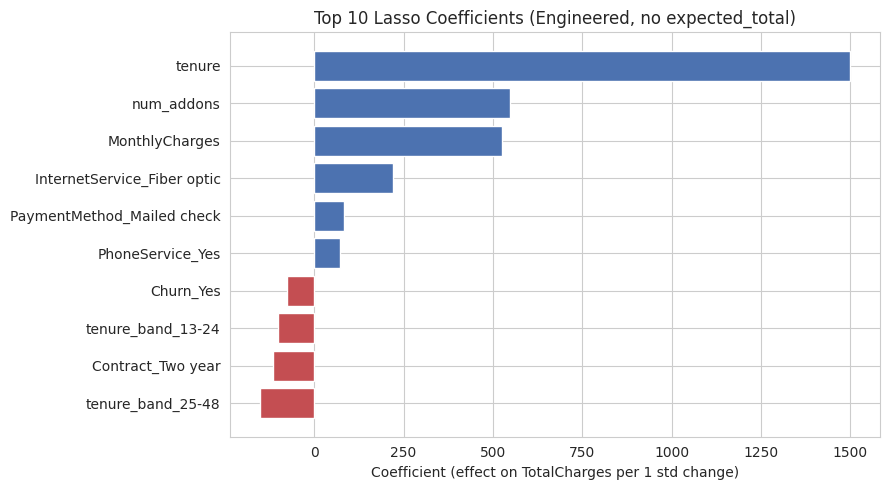

In [16]:
# Take the Lasso model trained WITHOUT expected_total, so we can see the other features.
# (With expected_total, Lasso keeps only 2 features, which is not very interesting to plot.)
lasso_step = fitted[("Engineered (no expected_total)", "Lasso")].named_steps["lassocv"]
coef = pd.Series(lasso_step.coef_, index=feature_sets["Engineered (no expected_total)"][0].columns)

# Keep the 10 features with the biggest effect (ignoring features Lasso set to zero)
top = coef[coef != 0].sort_values(key=abs, ascending=False).head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in top.values]   # red = lowers the total, blue = raises it
ax.barh(top.index, top.values, color=colors)
ax.set_title("Top 10 Lasso Coefficients (Engineered, no expected_total)")
ax.set_xlabel("Coefficient (effect on TotalCharges per 1 std change)")
plt.tight_layout()
plt.show()

## 2.7 Summary of Results and Insights

### Results at a glance

| Feature set | Model | Test R2 | Test RMSE | CV R2 (5-fold) |
|---|---|---|---|---|
| Baseline | Linear Regression | 0.9059 | 699.70 | 0.9075 |
| Baseline | Ridge | 0.9058 | 699.99 | 0.9074 |
| Baseline | Lasso | 0.9058 | 700.12 | 0.9075 |
| Engineered (no expected_total) | Linear Regression | 0.9090 | 688.18 | 0.9119 |
| Engineered (no expected_total) | Ridge | 0.9089 | 688.46 | 0.9119 |
| Engineered (no expected_total) | Lasso | 0.9085 | 690.04 | 0.9118 |
| Engineered (full) | Linear Regression | 0.9991 | 68.37 | 0.9991 |
| Engineered (full) | Ridge | 0.9991 | 68.37 | 0.9991 |
| Engineered (full) | **Lasso** | **0.9991** | **68.01** | **0.9991** |

### Which model performed best?
**Lasso Regression with the full engineered features** had the best score: test R2 of 0.9991 and test RMSE of about 68. That is roughly 3% of the average TotalCharges (about 2250). The baseline models were off by about 700 on average, which is about 31%. However, the difference between Linear, Ridge and Lasso is very small, so the better result comes from the features and not from the choice of model.

### Key insights
1. **Feature engineering made the biggest difference.** Adding expected_total (tenure x MonthlyCharges) cut the error by about 90%, from about 700 to about 68. A straight-line model cannot create a multiplication by itself, so we had to give it that feature. This is also why the baseline model predicted negative TotalCharges for some new customers.
2. **The other new features helped a little.** num_addons, has_support, contract_months and tenure_band raised R2 from 0.906 to 0.909 and lowered the error from about 700 to about 688. num_addons became the second most important feature in the Lasso chart.
3. **Model choice mattered very little here.** With over 7,000 customers and only a few dozen features, there is not much overfitting for Ridge or Lasso to fix. Lasso still gave us a useful result: with the full features, it removed 28 of 30 features and kept essentially one (expected_total), showing how much that one feature explains.
4. **The models generalize well.** The cross-validation scores are almost the same as the test scores (for example 0.9991 and 0.9991) and the CV standard deviation is tiny, so the models should work on customers they have not seen.
5. **Tenure, the number of add-on services and the monthly price drive the total.** These were the three biggest coefficients in the Lasso chart.

### Challenges and limitations
- **expected_total is almost the same as the target** (correlation 0.9996). It uses only tenure and MonthlyCharges, not TotalCharges, so it is not a leak, but it makes the final R2 look nearly perfect. That is why I also compared a version without it.
- **Changing the target.** In Deliverable 1 I

In [ ]:
# Save the regression results in a new variable so later code cannot overwrite them
regression_results = results.copy()

# Part 3: Classification, Clustering, and Pattern Mining

## 3.1 Project Overview

In this deliverable, we continue working with the Telco Customer Churn dataset used in Deliverables 1 and 2. The dataset contains 7,043 customer records and 21 attributes, including customer details, account information, subscribed services, and billing charges.

In Deliverable 1, we cleaned the dataset and explored the factors related to customer churn. In Deliverable 2, we developed regression models to predict TotalCharges and evaluated their performance.

For Deliverable 3, we focus on three data mining techniques:

1. **Classification:** Predict whether a customer will leave the telecom company using Decision Tree and K-Nearest Neighbors models.
2. **Clustering:** Use K-Means to identify groups of customers with similar characteristics.
3. **Association Rule Mining:** Use Apriori to discover relationships between customer services, contract types, and churn.

We will also perform hyperparameter tuning and evaluate the classification models using accuracy, F1 score, confusion matrices, and ROC curves.

Our goal is to understand customer behavior and identify useful patterns that telecom companies could use to improve customer retention.

## 3.2 Classification: Data Preparation

In this section, we prepare our dataset for customer churn classification.

We use Churn as our target variable, where:
- 0 represents customers who stayed.
- 1 represents customers who left.

We remove customerID because it is only a unique identifier and does not provide useful information for predicting churn.

We divide the dataset into 80% training data and 20% testing data. Stratified sampling helps maintain similar proportions of churned and non-churned customers in both datasets.

The training data will be used to develop our classification models, while the testing data will help us evaluate their performance on unseen customer records.

In [3]:
# Import the train-test split function
from sklearn.model_selection import train_test_split

# Separate the input features and target variable
X = df_clean.drop(columns=["customerID", "Churn"])

# Convert Churn into binary values
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

# Display customer churn distribution
print("\nChurn Distribution:")
print(y.value_counts())

print("\nChurn Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Training Features: (5634, 19)
Testing Features: (1409, 19)
Training Labels: (5634,)
Testing Labels: (1409,)

Churn Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Churn Percentage:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


### 3.2.1 Feature Encoding and Scaling

Our Telco Customer Churn dataset contains both numerical and categorical features. Before training classification models, we need to prepare these features.

We use the following preprocessing techniques:

1. **One-Hot Encoding:** Converts categorical features such as Contract, InternetService, and PaymentMethod into numerical columns that machine learning models can understand.

2. **Standard Scaling:** Standardizes numerical features such as tenure, MonthlyCharges, and TotalCharges. Scaling is especially important for K-Nearest Neighbors because it calculates distances between customers.

3. **ColumnTransformer:** Combines encoding and scaling into a single preprocessing process.

We will apply these preprocessing steps within machine learning pipelines so that transformations are learned only from training data. This helps prevent data leakage during model training and cross-validation.

In [7]:
# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Create preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Display selected features
print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))

print("\nPreprocessing pipeline created successfully!")

Numerical Features:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total Numerical Features: 3
Total Categorical Features: 16

Preprocessing pipeline created successfully!


C:\Users\kotap\AppData\Local\Temp\ipykernel_28768\2639240183.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


### 3.2.2 Building Classification Models

In this section, we develop two classification models to predict customer churn.

**1. Decision Tree Classifier**

The Decision Tree model makes predictions by dividing customer records into groups based on features such as contract type, tenure, and monthly charges. It is useful because its decision-making process is relatively easy to understand.

**2. K-Nearest Neighbors (KNN)**

KNN predicts whether a customer will leave by examining similar customers in the training dataset. We initially use five nearest neighbors.

We use Scikit-learn pipelines to combine preprocessing and classification. Both models are trained on the same training dataset to support a fair comparison.

We will evaluate their performance and apply hyperparameter tuning in the following sections.

In [8]:
# Import classification models and pipeline tools
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Create the Decision Tree classification pipeline
dt_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Create the K-Nearest Neighbors classification pipeline
knn_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train the Decision Tree model
dt_model.fit(X_train, y_train)
print("Decision Tree model trained successfully!")

# Train the KNN model
knn_model.fit(X_train, y_train)
print("K-Nearest Neighbors model trained successfully!")

# Generate predictions using the testing dataset
dt_predictions = dt_model.predict(X_test)
knn_predictions = knn_model.predict(X_test)

print("\nPredictions generated successfully!")

Decision Tree model trained successfully!
K-Nearest Neighbors model trained successfully!

Predictions generated successfully!


### 3.2.3 Classification Model Evaluation

After training the Decision Tree and K-Nearest Neighbors (KNN) models, we evaluate their performance using the testing dataset.

We use the following evaluation metrics:

1. **Accuracy:** Measures the percentage of correctly predicted customer churn outcomes.

2. **Precision:** Measures how many customers predicted to leave actually left.

3. **Recall:** Measures how many customers who actually left were correctly identified.

4. **F1 Score:** Combines precision and recall into a single score. This is especially useful because our dataset contains more customers who stayed than customers who left.

We compare both classification models using these metrics to understand how effectively they predict customer churn.

We focus particularly on the F1 score for customers who churned (Class 1), since identifying customers at risk of leaving is important for telecom companies.

In [9]:
# Import classification evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate performance metrics for both models
results = {
    "Model": ["Decision Tree", "K-Nearest Neighbors"],
    "Accuracy": [
        accuracy_score(y_test, dt_predictions),
        accuracy_score(y_test, knn_predictions)
    ],
    "Precision": [
        precision_score(y_test, dt_predictions),
        precision_score(y_test, knn_predictions)
    ],
    "Recall": [
        recall_score(y_test, dt_predictions),
        recall_score(y_test, knn_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, dt_predictions),
        f1_score(y_test, knn_predictions)
    ]
}

# Create a comparison table
results_df = pd.DataFrame(results)

print("Classification Model Performance Comparison:")
display(results_df.round(4))

# Display detailed classification reports
print("\nDecision Tree Classification Report:")
print(classification_report(y_test, dt_predictions))

print("\nK-Nearest Neighbors Classification Report:")
print(classification_report(y_test, knn_predictions))

Classification Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.7303,0.4921,0.5027,0.4974
1,K-Nearest Neighbors,0.7587,0.5447,0.5535,0.5491



Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.81      0.82      1035
           1       0.49      0.50      0.50       374

    accuracy                           0.73      1409
   macro avg       0.66      0.66      0.66      1409
weighted avg       0.73      0.73      0.73      1409


K-Nearest Neighbors Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.83      0.84      1035
           1       0.54      0.55      0.55       374

    accuracy                           0.76      1409
   macro avg       0.69      0.69      0.69      1409
weighted avg       0.76      0.76      0.76      1409



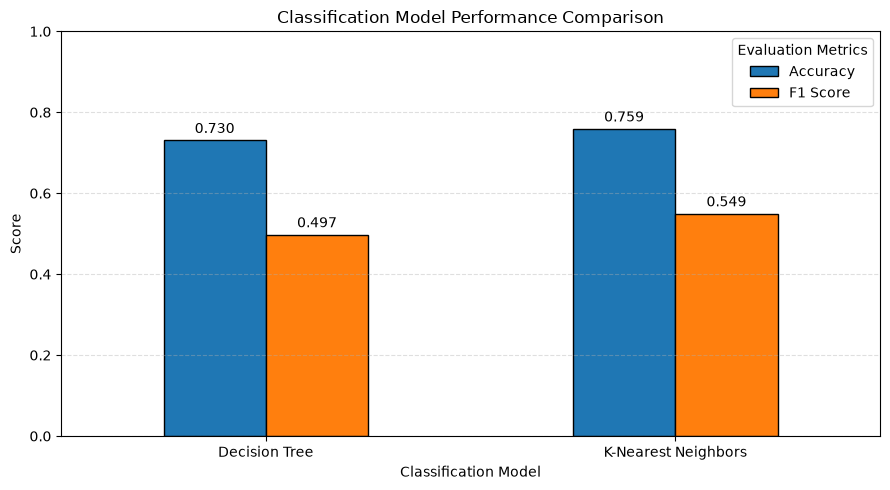

In [10]:
# Compare Accuracy and F1 Score visually
plot_data = results_df.set_index("Model")[
    ["Accuracy", "F1 Score"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0,
    edgecolor="black"
)

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classification Model")
plt.ylim(0, 1)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Add score labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

### 3.2.4 Interpretation of Classification Results

After evaluating both classification models, we found that K-Nearest Neighbors (KNN) performed better than the Decision Tree model.

The Decision Tree model achieved an accuracy of 73.03% and an F1 score of 49.74%. In comparison, KNN achieved a higher accuracy of 75.87% and an F1 score of 54.91%.

KNN also performed better in precision and recall, showing that it was more effective at identifying customers who left the telecom company.

However, both models had difficulty identifying all customers who churned. This may be partly related to the imbalance in our dataset, where most customers did not churn.

Based on these results, KNN is the better-performing baseline model. We will explore hyperparameter tuning to see whether classification performance can be improved.

### 3.2.5 Confusion Matrix and ROC Curve Evaluation

To better understand the performance of our classification models, we use confusion matrices and Receiver Operating Characteristic (ROC) curves.

**Confusion Matrix:**

A confusion matrix shows the number of correct and incorrect predictions made by a classification model.

- True Negative (TN): Customers correctly predicted to stay.
- True Positive (TP): Customers correctly predicted to leave.
- False Positive (FP): Customers incorrectly predicted to leave.
- False Negative (FN): Customers who left but were predicted to stay.

**ROC Curve:**

The ROC curve shows how well a classification model distinguishes between customers who stay and customers who leave across different classification thresholds.

We also calculate the Area Under the Curve (AUC). A higher AUC indicates better overall separation between the two customer groups.

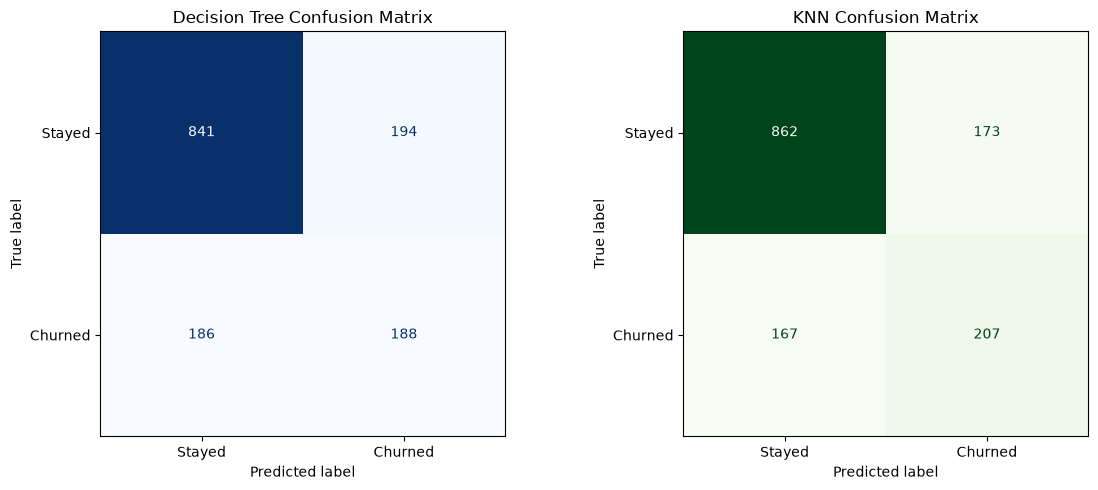

In [11]:
# Import confusion matrix visualization tool
from sklearn.metrics import ConfusionMatrixDisplay

# Create confusion matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Decision Tree confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Decision Tree Confusion Matrix")

# KNN confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("KNN Confusion Matrix")

plt.tight_layout()
plt.show()

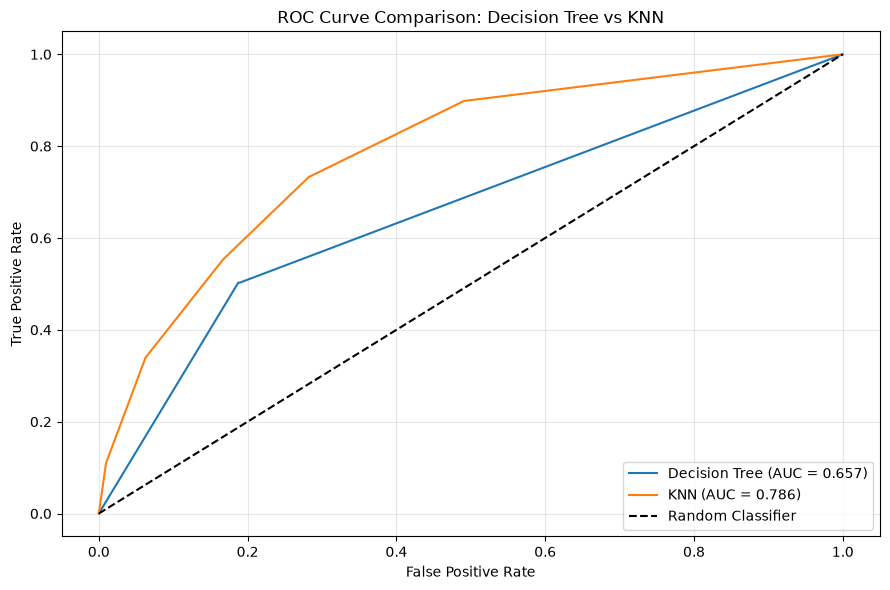

Decision Tree AUC: 0.6571
KNN AUC: 0.7865


In [12]:
# Import ROC curve evaluation metrics
from sklearn.metrics import roc_curve, roc_auc_score

# Get predicted probabilities for customers who churned
dt_probabilities = dt_model.predict_proba(X_test)[:, 1]
knn_probabilities = knn_model.predict_proba(X_test)[:, 1]

# Calculate ROC curve coordinates
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_probabilities)
knn_fpr, knn_tpr, _ = roc_curve(y_test, knn_probabilities)

# Calculate AUC scores
dt_auc = roc_auc_score(y_test, dt_probabilities)
knn_auc = roc_auc_score(y_test, knn_probabilities)

# Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(
    dt_fpr, dt_tpr,
    label=f"Decision Tree (AUC = {dt_auc:.3f})"
)

plt.plot(
    knn_fpr, knn_tpr,
    label=f"KNN (AUC = {knn_auc:.3f})"
)

# Reference line for random classification
plt.plot(
    [0, 1], [0, 1],
    "k--", label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison: Decision Tree vs KNN")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print AUC scores
print(f"Decision Tree AUC: {dt_auc:.4f}")
print(f"KNN AUC: {knn_auc:.4f}")

### 3.2.6 Interpretation of Confusion Matrix and ROC Results

After analyzing the confusion matrices, we observed that K-Nearest Neighbors (KNN) performed better than the Decision Tree model.

The Decision Tree correctly identified 188 customers who churned but failed to identify 186 customers who actually left. In comparison, KNN correctly identified 207 churned customers and missed 167.

The ROC curve also showed a difference in performance. Decision Tree achieved an AUC score of 0.6571, while KNN achieved a higher AUC score of 0.7865.

These results suggest that KNN is better at distinguishing between customers who stay and customers who leave.

However, both models still miss some customers who churn. We will perform hyperparameter tuning on the Decision Tree model to see whether adjusting its settings can improve performance.

### 3.2.7 Hyperparameter Tuning Using GridSearchCV

In this section, we perform hyperparameter tuning on the Decision Tree classifier using GridSearchCV.

Hyperparameter tuning helps us identify model settings that may improve classification performance.

We test the following parameters:

1. **max_depth:** Controls the maximum depth of the Decision Tree. Limiting tree depth can help reduce overfitting.

2. **min_samples_split:** Specifies the minimum number of samples required to split a node.

3. **min_samples_leaf:** Specifies the minimum number of samples required at each leaf node.

4. **class_weight:** Tests whether balancing the importance of churned and non-churned customers improves classification.

We use 5-fold stratified cross-validation and F1 score to select the best parameters.

We focus on F1 score because identifying customers who churn is important, and our dataset contains an unequal number of churned and non-churned customers.

After tuning, we compare the optimized Decision Tree with the original model using the held-out testing dataset.

In [13]:
# Import tools for hyperparameter tuning
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Create a Decision Tree pipeline for tuning
dt_tuning_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Define the hyperparameter search space
param_grid = {
    "classifier__max_depth": [3, 5, 10],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 5, 10],
    "classifier__class_weight": [None, "balanced"]
}

# Use stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Configure GridSearchCV
grid_search = GridSearchCV(
    estimator=dt_tuning_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    refit=True
)

# Perform hyperparameter tuning on training data
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best Hyperparameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))

# Get the best tuned Decision Tree
best_dt_model = grid_search.best_estimator_

# Predict using the testing dataset
tuned_dt_predictions = best_dt_model.predict(X_test)
tuned_dt_probabilities = best_dt_model.predict_proba(X_test)[:, 1]

# Evaluate the tuned model
tuned_accuracy = accuracy_score(y_test, tuned_dt_predictions)
tuned_f1 = f1_score(y_test, tuned_dt_predictions)
tuned_auc = roc_auc_score(y_test, tuned_dt_probabilities)

print("\nTuned Decision Tree Performance:")
print(f"Accuracy: {tuned_accuracy:.4f}")
print(f"F1 Score: {tuned_f1:.4f}")
print(f"ROC-AUC: {tuned_auc:.4f}")

Best Hyperparameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Best Cross-Validation F1 Score:
0.6194

Tuned Decision Tree Performance:
Accuracy: 0.7459
F1 Score: 0.6208
ROC-AUC: 0.8162


### 3.2.8 Hyperparameter Tuning Results and Model Comparison

We used GridSearchCV with five-fold stratified cross-validation to optimize the Decision Tree classifier.

The best combination included a maximum tree depth of 3, a minimum of 2 samples required for splitting, a minimum of 1 sample per leaf, and balanced class weights.

The tuned Decision Tree achieved an accuracy of 74.59%, an F1 score of 62.08%, and an ROC-AUC score of 0.8162.

Compared with the original Decision Tree, the tuned model improved its F1 score from 49.74% to 62.08%. Its ROC-AUC score also increased from 0.6571 to 0.8162.

Although KNN achieved slightly higher accuracy at 75.87%, the tuned Decision Tree produced the highest F1 score and ROC-AUC of the three models.

Based on these results, we selected the tuned Decision Tree as our preferred classification model because it provides a better balance between precision and recall for identifying customer churn.

Final Classification Model Comparison:


,Model,Accuracy,F1 Score,ROC-AUC
0,Decision Tree,0.7303,0.4974,0.6571
1,KNN,0.7587,0.5491,0.7865
2,Tuned Decision Tree,0.7459,0.6208,0.8162


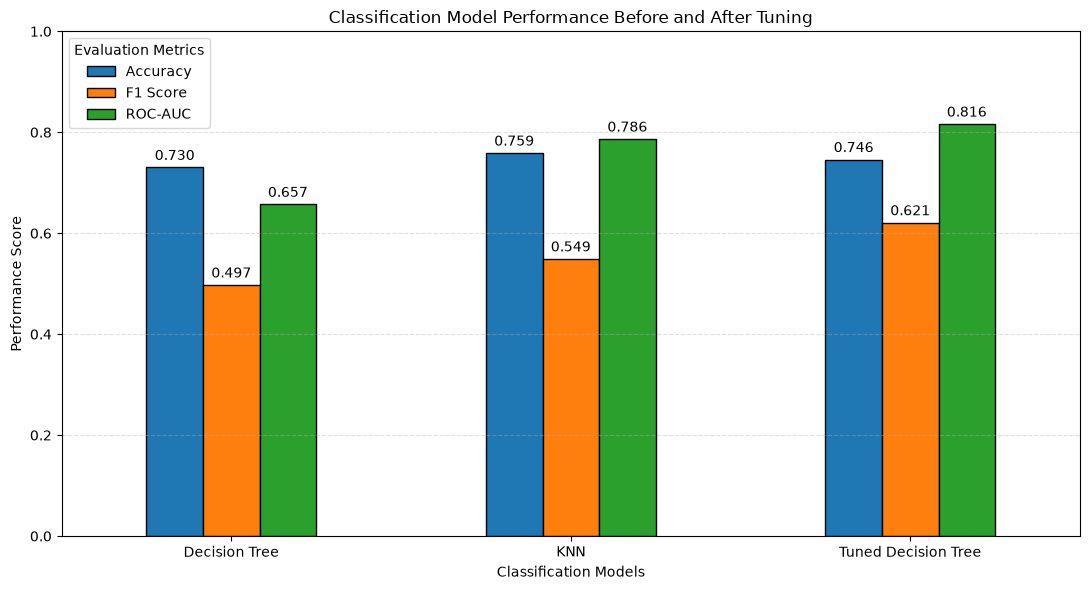

In [14]:
# Compare original Decision Tree, KNN, and tuned Decision Tree
comparison_df = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "KNN",
        "Tuned Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_test, dt_predictions),
        accuracy_score(y_test, knn_predictions),
        tuned_accuracy
    ],
    "F1 Score": [
        f1_score(y_test, dt_predictions),
        f1_score(y_test, knn_predictions),
        tuned_f1
    ],
    "ROC-AUC": [
        dt_auc,
        knn_auc,
        tuned_auc
    ]
})

print("Final Classification Model Comparison:")
display(comparison_df.round(4))

# Visualize classification model performance
ax = comparison_df.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6),
    rot=0,
    edgecolor="black"
)

plt.title("Classification Model Performance Before and After Tuning")
plt.xlabel("Classification Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Display scores above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

## 3.3 Customer Segmentation Using K-Means Clustering

In this section, we use K-Means clustering to group customers based on similar characteristics.

Unlike classification, clustering is an unsupervised learning technique. It identifies groups of customers without using their churn labels to create those groups.

For our analysis, we selected the following customer features:

- tenure
- MonthlyCharges
- Contract
- InternetService
- OnlineSecurity
- TechSupport
- PaymentMethod

These features help us understand customer relationships, service usage, billing patterns, and contract preferences.

We exclude customerID and Churn from the clustering process because customerID is only an identifier, while Churn will be used later to understand the characteristics of the discovered customer groups.

We apply standard scaling to numerical features and one-hot encoding to categorical features.

To determine a suitable number of clusters, we compare the Elbow Method and Silhouette Scores for different values of K.

In [15]:
# Import preprocessing tools for clustering
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Select features for customer segmentation
cluster_features = [
    "tenure",
    "MonthlyCharges",
    "Contract",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod"
]

# Create a separate dataset for clustering
cluster_df = df_clean[cluster_features].copy()

# Identify numerical and categorical columns
cluster_num = ["tenure", "MonthlyCharges"]

cluster_cat = [
    "Contract",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod"
]

# Create the clustering preprocessing pipeline
cluster_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), cluster_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         cluster_cat)
    ]
)

# Apply scaling and encoding
X_cluster = cluster_preprocessor.fit_transform(cluster_df)

# Display the processed dataset dimensions
print("Original Clustering Data Shape:", cluster_df.shape)
print("Processed Clustering Data Shape:", X_cluster.shape)

print("\nClustering data prepared successfully!")

Original Clustering Data Shape: (7043, 7)
Processed Clustering Data Shape: (7043, 16)

Clustering data prepared successfully!


K = 2, Silhouette Score = 0.2216
K = 3, Silhouette Score = 0.2702
K = 4, Silhouette Score = 0.2697
K = 5, Silhouette Score = 0.2698
K = 6, Silhouette Score = 0.2831


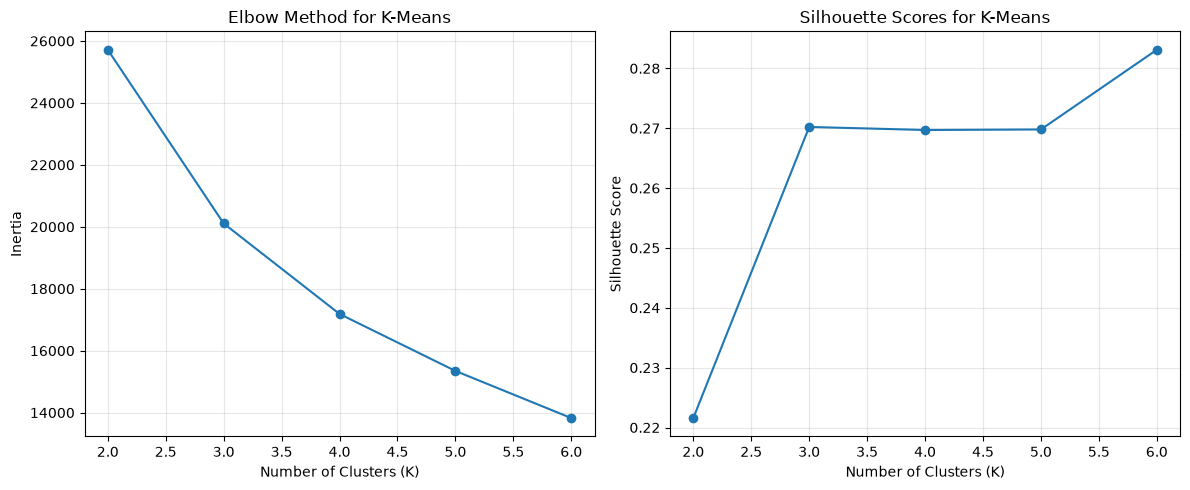

In [16]:
# Import K-Means and evaluation metric
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different cluster numbers
k_values = range(2, 7)

inertia_values = []
silhouette_scores = []

for k in k_values:

    # Create and train K-Means model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    # Calculate inertia for Elbow Method
    inertia_values.append(kmeans.inertia_)

    # Calculate Silhouette Score using a sample
    score = silhouette_score(
        X_cluster,
        cluster_labels,
        sample_size=1000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Visualize Elbow Method and Silhouette Scores
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Elbow Method
axes[0].plot(
    list(k_values),
    inertia_values,
    marker="o"
)
axes[0].set_title("Elbow Method for K-Means")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

# Silhouette Score
axes[1].plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)
axes[1].set_title("Silhouette Scores for K-Means")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 3.3.1 Selecting the Optimal Number of Clusters

We evaluated K-Means clustering using the Elbow Method and Silhouette Scores for different numbers of clusters.

The Elbow Method helps us understand how the clustering inertia changes as the number of clusters increases.

The Silhouette Score measures how closely customers are grouped within their assigned clusters compared with other clusters.

For our analysis, we select the number of clusters with the highest Silhouette Score among the tested values.

We then train the final K-Means model using this selected number of clusters.

In [17]:
# Select the number of clusters with the highest Silhouette Score
best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Selected Number of Clusters:", best_k)
print("Best Silhouette Score:", round(max(silhouette_scores), 4))

# Train the final K-Means model
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# Predict cluster assignments
final_cluster_labels = final_kmeans.fit_predict(X_cluster)

# Create a copy of the cleaned dataset
cluster_results = df_clean.copy()

# Add cluster labels
cluster_results["Cluster"] = final_cluster_labels

# Display cluster sizes
print("\nCustomers in Each Cluster:")
print(cluster_results["Cluster"].value_counts().sort_index())

print("\nK-Means clustering completed successfully!")

Selected Number of Clusters: 6
Best Silhouette Score: 0.2831

Customers in Each Cluster:
Cluster
0    1088
1    1316
2    1848
3     682
4    1248
5     861
Name: count, dtype: int64

K-Means clustering completed successfully!


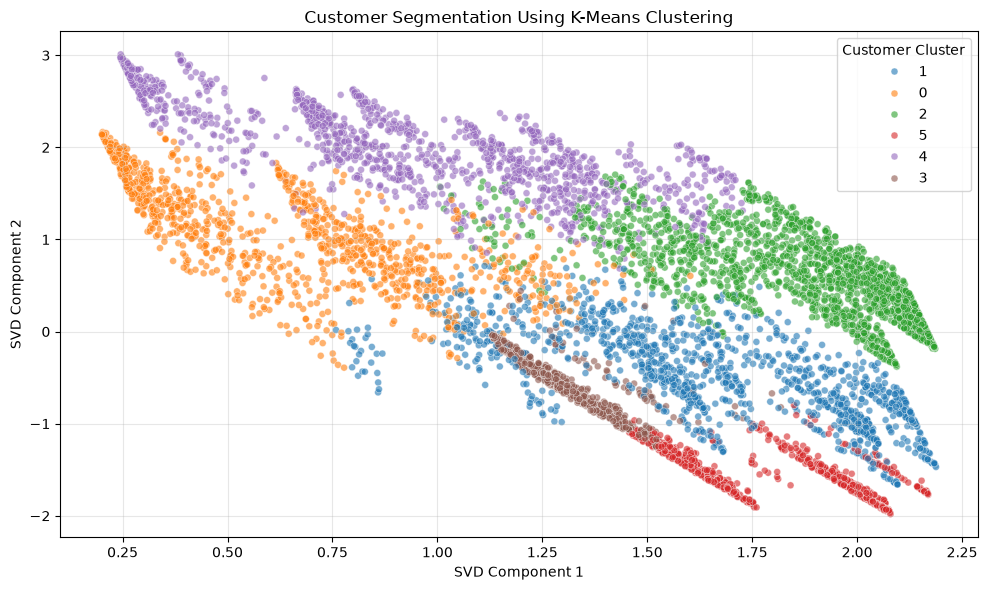

In [18]:
# Import dimensionality reduction tool
from sklearn.decomposition import TruncatedSVD

# Reduce the processed clustering data to two dimensions
# This helps us visualize the clusters in a 2D graph
svd = TruncatedSVD(
    n_components=2,
    random_state=42
)

X_cluster_2d = svd.fit_transform(X_cluster)

# Create a dataframe for visualization
cluster_plot_df = pd.DataFrame({
    "Component 1": X_cluster_2d[:, 0],
    "Component 2": X_cluster_2d[:, 1],
    "Cluster": final_cluster_labels.astype(str)
})

# Visualize customer clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cluster_plot_df,
    x="Component 1",
    y="Component 2",
    hue="Cluster",
    palette="tab10",
    alpha=0.6,
    s=25
)

plt.title("Customer Segmentation Using K-Means Clustering")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.legend(title="Customer Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Customer Cluster Characteristics:


,Customer_Count,Average_Tenure,Average_MonthlyCharges,Churn_Rate,Common_Contract
Cluster,,,,,
0,1088,55.33,67.97,4.96,Two year
1,1316,13.97,50.22,30.62,Month-to-month
2,1848,15.81,85.41,58.33,Month-to-month
3,682,54.81,22.20,1.61,Two year
4,1248,58.25,100.51,17.55,One year
5,861,11.75,20.51,12.08,Month-to-month


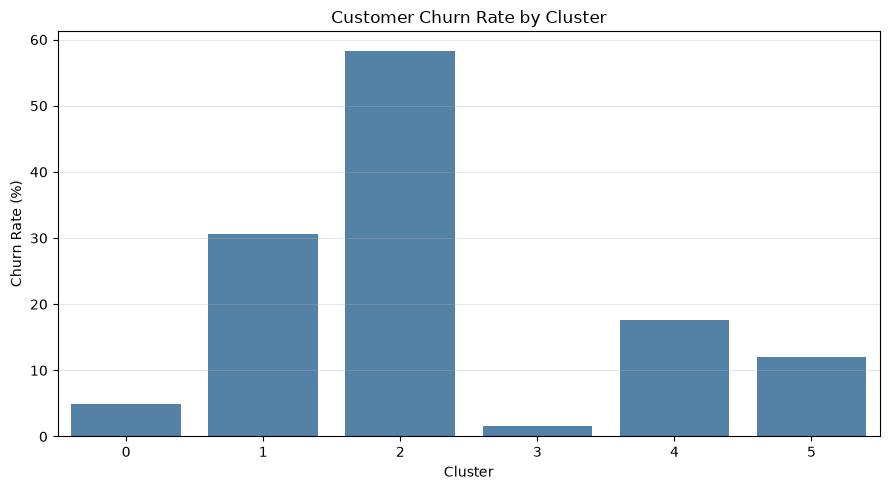

In [19]:
# Summarize the characteristics of each customer cluster
cluster_summary = cluster_results.groupby("Cluster").agg(
    Customer_Count=("Churn", "count"),
    Average_Tenure=("tenure", "mean"),
    Average_MonthlyCharges=("MonthlyCharges", "mean"),
    Churn_Rate=("Churn", lambda x: (x == "Yes").mean() * 100),
    Common_Contract=("Contract", lambda x: x.mode().iloc[0])
)

# Display the customer segment summary
print("Customer Cluster Characteristics:")
display(cluster_summary.round(2))

# Visualize churn percentages across clusters
plt.figure(figsize=(9, 5))

sns.barplot(
    x=cluster_summary.index,
    y=cluster_summary["Churn_Rate"],
    color="steelblue"
)

plt.title("Customer Churn Rate by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Churn Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 3.4 Association Rule Mining Using Apriori

In this section, we apply the Apriori algorithm to identify meaningful relationships between customer characteristics and churn.

Association rule mining helps us discover combinations of customer attributes that frequently occur together.

We focus on the following features:

- Contract
- InternetService
- OnlineSecurity
- TechSupport
- PaymentMethod
- PaperlessBilling
- Churn

The Apriori algorithm identifies frequent itemsets and generates association rules using three main measures:

1. **Support:** Measures how frequently a combination of attributes appears in the dataset.

2. **Confidence:** Measures how often the consequence of a rule occurs when its conditions are present.

3. **Lift:** Measures the strength of an association compared with what would be expected if the attributes were independent. A lift greater than 1 indicates a positive association.

Our goal is to identify customer characteristics associated with higher churn rates. These patterns may help telecom companies design customer retention strategies.

Association rules describe relationships in the data, but they do not establish cause and effect.

In [20]:
# Import libraries for association rule mining
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# Select categorical attributes for pattern mining
association_features = [
    "Contract",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod",
    "PaperlessBilling",
    "Churn"
]

# Create a separate dataset for association rules
association_df = df_clean[association_features].copy()

# Convert each customer record into a transaction
# Column names are included to distinguish attribute values
transactions = []

for _, row in association_df.iterrows():
    transaction = [
        f"{column}={row[column]}"
        for column in association_features
    ]
    transactions.append(transaction)

# Convert transactions into a one-hot encoded format
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)

association_encoded = pd.DataFrame(
    te_array,
    columns=te.columns_
)

# Display the processed dataset
print("Association Rule Mining Dataset Shape:")
print(association_encoded.shape)

print("\nTransaction Encoding Completed Successfully!")

display(association_encoded.head())

Association Rule Mining Dataset Shape:
(7043, 18)

Transaction Encoding Completed Successfully!


,Churn=No,Churn=Yes,Contract=Month-to-month,Contract=One year,Contract=Two year,InternetService=DSL,InternetService=Fiber optic,InternetService=No,OnlineSecurity=No,OnlineSecurity=Yes,PaperlessBilling=No,PaperlessBilling=Yes,PaymentMethod=Bank transfer (automatic),PaymentMethod=Credit card (automatic),PaymentMethod=Electronic check,PaymentMethod=Mailed check,TechSupport=No,TechSupport=Yes
0,True,False,True,False,False,True,False,False,True,False,False,True,False,False,True,False,True,False
1,True,False,False,True,False,True,False,False,False,True,True,False,False,False,False,True,True,False
2,False,True,True,False,False,True,False,False,False,True,False,True,False,False,False,True,True,False
3,True,False,False,True,False,True,False,False,False,True,True,False,True,False,False,False,False,True
4,False,True,True,False,False,False,True,False,True,False,False,True,False,False,True,False,True,False


In [21]:
# Identify frequent itemsets using Apriori
frequent_itemsets = apriori(
    association_encoded,
    min_support=0.02,
    use_colnames=True,
    max_len=3
)

print("Number of Frequent Itemsets:", len(frequent_itemsets))

# Generate association rules based on confidence
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.40
)

# Focus on rules associated with customers who churned
churn_rules = rules[
    rules["consequents"].apply(
        lambda x: x == frozenset({"Churn=Yes"})
    )
].copy()

# Keep only rules indicating a positive association
churn_rules = churn_rules[
    churn_rules["lift"] > 1
].copy()

# Sort rules by lift and confidence
churn_rules = churn_rules.sort_values(
    by=["lift", "confidence"],
    ascending=False
)

# Make the rules easier to read
churn_rules["Antecedents"] = churn_rules[
    "antecedents"
].apply(lambda x: ", ".join(sorted(x)))

# Display important columns
print("\nTop Association Rules Related to Customer Churn:")

display(
    churn_rules[
        ["Antecedents", "support", "confidence", "lift"]
    ].head(10).round(4)
)

Number of Frequent Itemsets: 595

Top Association Rules Related to Customer Churn:


,Antecedents,support,confidence,lift
342,"Contract=Month-to-month, InternetService=Fiber...",0.1650,0.5461,2.0577
358,"Contract=Month-to-month, PaymentMethod=Electro...",0.1411,0.5373,2.0247
385,"InternetService=Fiber optic, PaymentMethod=Ele...",0.1205,0.5323,2.0058
428,"PaymentMethod=Electronic check, TechSupport=No",0.1328,0.5049,1.9025
402,"OnlineSecurity=No, PaymentMethod=Electronic check",0.1330,0.5048,1.9024
416,"PaperlessBilling=Yes, PaymentMethod=Electronic...",0.1231,0.4977,1.8755
389,"InternetService=Fiber optic, TechSupport=No",0.1563,0.4937,1.8605
373,"InternetService=Fiber optic, OnlineSecurity=No",0.1582,0.4936,1.8600
352,"Contract=Month-to-month, PaperlessBilling=Yes",0.1773,0.4830,1.8200
346,"Contract=Month-to-month, OnlineSecurity=No",0.2047,0.4571,1.7223


### 3.4.1 Association Rule Visualization and Analysis

After applying the Apriori algorithm, we analyze the association rules related to customer churn.

We focus on rules with a lift greater than 1 because they indicate a positive association between certain customer characteristics and churn.

To understand these relationships, we visualize the strongest rules using:

1. **Lift Comparison:** Compares the strength of the top association rules.
2. **Support vs. Confidence:** Shows how frequently the rules occur and how reliably their conditions are associated with churn.

These visualizations help us identify combinations of customer characteristics that may be useful for customer retention planning.

We also compare the confidence of the discovered rules with the overall churn rate to understand whether the identified customer groups have higher-than-average churn.

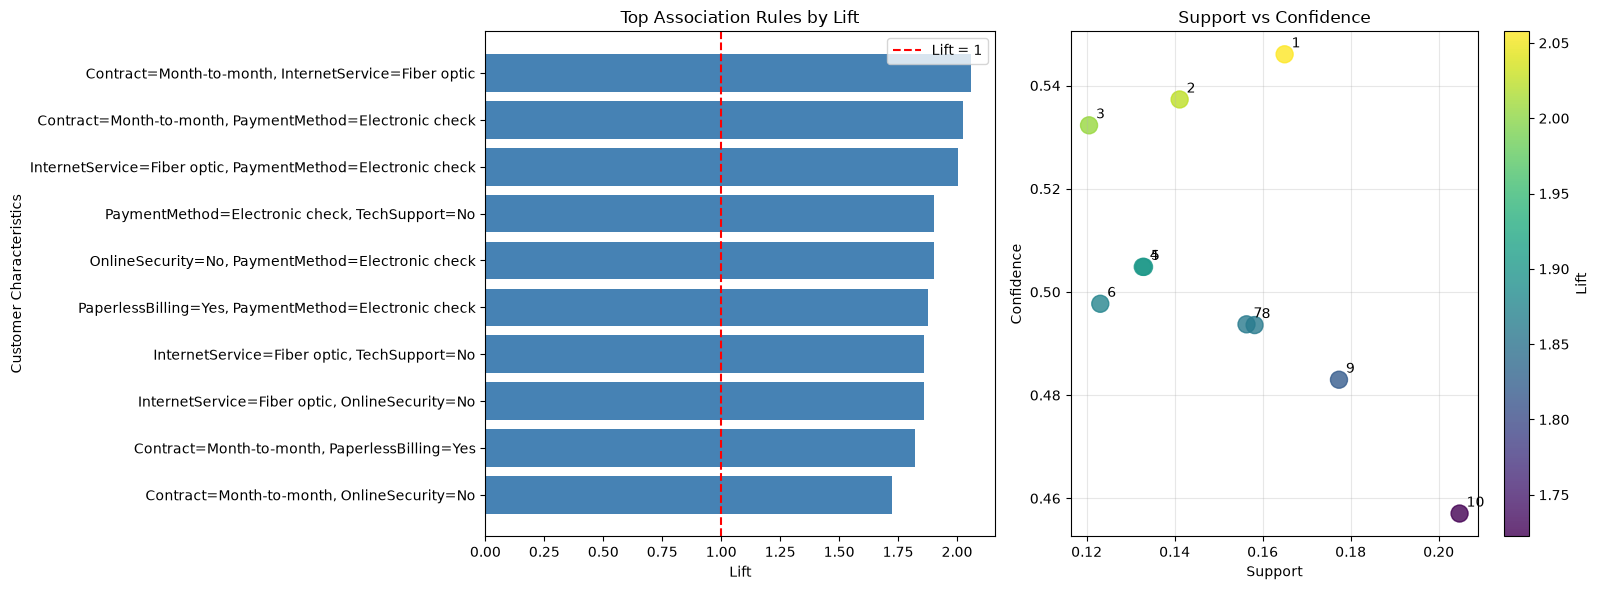

Association rule visualizations completed!


In [22]:
# Select the top 10 association rules
top_rules = churn_rules.head(10).copy()

if top_rules.empty:
    print("No churn-related rules met the selected thresholds.")
    print("Consider adjusting minimum support or confidence.")
else:
    # Create two visualizations
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Visualization 1: Lift of top association rules
    axes[0].barh(
        top_rules["Antecedents"][::-1],
        top_rules["lift"][::-1],
        color="steelblue"
    )

    axes[0].axvline(
        x=1,
        color="red",
        linestyle="--",
        label="Lift = 1"
    )

    axes[0].set_title("Top Association Rules by Lift")
    axes[0].set_xlabel("Lift")
    axes[0].set_ylabel("Customer Characteristics")
    axes[0].legend()

    # Visualization 2: Support vs Confidence
    scatter = axes[1].scatter(
        top_rules["support"],
        top_rules["confidence"],
        c=top_rules["lift"],
        s=150,
        cmap="viridis",
        alpha=0.8
    )

    # Add rule numbers
    for i, (_, rule) in enumerate(top_rules.iterrows(), 1):
        axes[1].annotate(
            str(i),
            (rule["support"], rule["confidence"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

    axes[1].set_title("Support vs Confidence")
    axes[1].set_xlabel("Support")
    axes[1].set_ylabel("Confidence")
    axes[1].grid(alpha=0.3)

    plt.colorbar(scatter, ax=axes[1], label="Lift")

    plt.tight_layout()
    plt.show()

    print("Association rule visualizations completed!")

In [23]:
# Calculate the overall customer churn rate
overall_churn_rate = (
    df_clean["Churn"].eq("Yes").mean()
)

print(
    f"Overall Customer Churn Rate: "
    f"{overall_churn_rate:.2%}"
)

# Interpret the strongest churn-related rules
if top_rules.empty:
    print("\nNo association rules available to interpret.")
else:
    print("\nTop 5 Association Rule Interpretations:\n")

    for i, (_, rule) in enumerate(
        top_rules.head(5).iterrows(), 1
    ):
        print(f"Rule {i}:")
        print(f"Customer Characteristics: {rule['Antecedents']}")
        print(f"Support: {rule['support']:.2%}")
        print(f"Confidence: {rule['confidence']:.2%}")
        print(f"Lift: {rule['lift']:.2f}")

        print(
            f"Interpretation: Among customers matching "
            f"these characteristics, "
            f"{rule['confidence']:.2%} churned, "
            f"compared with {overall_churn_rate:.2%} "
            f"across all customers."
        )

        print("-" * 60)

Overall Customer Churn Rate: 26.54%

Top 5 Association Rule Interpretations:

Rule 1:
Customer Characteristics: Contract=Month-to-month, InternetService=Fiber optic
Support: 16.50%
Confidence: 54.61%
Lift: 2.06
Interpretation: Among customers matching these characteristics, 54.61% churned, compared with 26.54% across all customers.
------------------------------------------------------------
Rule 2:
Customer Characteristics: Contract=Month-to-month, PaymentMethod=Electronic check
Support: 14.11%
Confidence: 53.73%
Lift: 2.02
Interpretation: Among customers matching these characteristics, 53.73% churned, compared with 26.54% across all customers.
------------------------------------------------------------
Rule 3:
Customer Characteristics: InternetService=Fiber optic, PaymentMethod=Electronic check
Support: 12.05%
Confidence: 53.23%
Lift: 2.01
Interpretation: Among customers matching these characteristics, 53.23% churned, compared with 26.54% across all customers.
----------------------

## 3.5 Final Findings and Real-World Applications

In this project, we applied classification, clustering, and association rule mining techniques to the Telco Customer Churn dataset.

Our analysis focused on three main objectives:

1. **Classification:** Predict which customers are likely to leave the telecom company.
2. **Clustering:** Identify customer groups with similar account and service characteristics.
3. **Association Rule Mining:** Discover relationships between customer characteristics and churn.

We evaluated our models using appropriate performance metrics and explored how the findings could support real-world customer retention decisions.

The following sections summarize our results, practical applications, challenges, and possible improvements.

In [25]:
# Summarize all major findings from Deliverable 3

print("=" * 60)
print("DELIVERABLE 3 - FINAL RESULTS SUMMARY")
print("=" * 60)

# 1. Classification results
print("\n1. CLASSIFICATION MODEL PERFORMANCE")
display(comparison_df.round(4))

# 2. Best classification model based on F1 score
best_model = comparison_df.loc[
    comparison_df["F1 Score"].idxmax()
]

print("\nBest Classification Model:")
print(best_model["Model"])
print(f"Accuracy: {best_model['Accuracy']:.2%}")
print(f"F1 Score: {best_model['F1 Score']:.2%}")
print(f"ROC-AUC: {best_model['ROC-AUC']:.4f}")

# 3. Clustering results
print("\n2. K-MEANS CLUSTERING RESULTS")
print("Selected Number of Clusters:", best_k)

display(cluster_summary.round(2))

# Identify the cluster with the highest churn rate
highest_churn_cluster = cluster_summary[
    "Churn_Rate"
].idxmax()

print("\nCluster with Highest Churn Rate:")
print("Cluster:", highest_churn_cluster)
print(
    "Churn Rate:",
    round(
        cluster_summary.loc[
            highest_churn_cluster, "Churn_Rate"
        ], 2
    ),
    "%"
)

# 4. Association rule mining results
print("\n3. ASSOCIATION RULE MINING RESULTS")

if churn_rules.empty:
    print("No churn-related rules met the selected thresholds.")
else:
    print("Total Churn-Related Rules:", len(churn_rules))

    print("\nTop 5 Association Rules:")
    display(
        churn_rules[
            ["Antecedents", "support", "confidence", "lift"]
        ].head(5).round(4)
    )

print("\nFinal results summary generated successfully!")

DELIVERABLE 3 - FINAL RESULTS SUMMARY

1. CLASSIFICATION MODEL PERFORMANCE


,Model,Accuracy,F1 Score,ROC-AUC
0,Decision Tree,0.7303,0.4974,0.6571
1,KNN,0.7587,0.5491,0.7865
2,Tuned Decision Tree,0.7459,0.6208,0.8162



Best Classification Model:
Tuned Decision Tree
Accuracy: 74.59%
F1 Score: 62.08%
ROC-AUC: 0.8162

2. K-MEANS CLUSTERING RESULTS
Selected Number of Clusters: 6


,Customer_Count,Average_Tenure,Average_MonthlyCharges,Churn_Rate,Common_Contract
Cluster,,,,,
0,1088,55.33,67.97,4.96,Two year
1,1316,13.97,50.22,30.62,Month-to-month
2,1848,15.81,85.41,58.33,Month-to-month
3,682,54.81,22.20,1.61,Two year
4,1248,58.25,100.51,17.55,One year
5,861,11.75,20.51,12.08,Month-to-month



Cluster with Highest Churn Rate:
Cluster: 2
Churn Rate: 58.33 %

3. ASSOCIATION RULE MINING RESULTS
Total Churn-Related Rules: 17

Top 5 Association Rules:


,Antecedents,support,confidence,lift
342,"Contract=Month-to-month, InternetService=Fiber...",0.1650,0.5461,2.0577
358,"Contract=Month-to-month, PaymentMethod=Electro...",0.1411,0.5373,2.0247
385,"InternetService=Fiber optic, PaymentMethod=Ele...",0.1205,0.5323,2.0058
428,"PaymentMethod=Electronic check, TechSupport=No",0.1328,0.5049,1.9025
402,"OnlineSecurity=No, PaymentMethod=Electronic check",0.1330,0.5048,1.9024



Final results summary generated successfully!


### 3.5.1 Key Findings

In Deliverable 3, we applied classification, clustering, and association rule mining techniques to better understand customer churn in the Telco Customer Churn dataset.

**Classification Results**

We developed Decision Tree and K-Nearest Neighbors (KNN) classification models to predict customer churn.

The original Decision Tree achieved an accuracy of 73.03% and an F1 score of 49.74%. KNN performed better initially, achieving an accuracy of 75.87% and an F1 score of 54.91%.

After applying GridSearchCV hyperparameter tuning, the Decision Tree improved to an accuracy of 74.59%, an F1 score of 62.08%, and a ROC-AUC score of 0.8162.

Although KNN achieved slightly higher accuracy, the tuned Decision Tree provided the best F1 score and ROC-AUC. This suggests that hyperparameter tuning helped improve the model's ability to identify customers at risk of leaving.

**Clustering Results**

We applied K-Means clustering to group customers based on tenure, monthly charges, contract type, internet service, security features, technical support, and payment method.

We used the Elbow Method and Silhouette Scores to evaluate different numbers of clusters.

We then compared the resulting customer groups based on average tenure, monthly charges, contract type, and churn percentage.

This analysis provides a way to identify different customer segments and examine which groups may require additional retention efforts.

**Association Rule Mining Results**

We applied the Apriori algorithm to discover associations between customer characteristics and churn.

We evaluated association rules using support, confidence, and lift.

By examining rules with lift greater than 1, we focused on customer characteristics associated with above-average churn.

These relationships can help telecom companies investigate potential customer retention risks. However, association rules show statistical relationships rather than direct causes of churn.

### 3.5.2 Real-World Applications and Recommendations

The findings from our project could help telecom companies make data-driven decisions about customer retention.

**1. Early Identification of Customer Churn**

The tuned Decision Tree classification model could help identify customers who are more likely to leave. Companies could use these predictions to prioritize customers for retention campaigns.

**2. Customer Segmentation**

K-Means clustering allows telecom companies to examine different groups of customers based on their account characteristics and service preferences.

Customer segments with higher observed churn rates could be investigated further to understand their needs and develop appropriate retention strategies.

**3. Personalized Customer Support**

Association rule mining helps identify combinations of customer characteristics associated with churn.

Telecom companies could use these patterns to explore targeted customer support programs, service improvements, or contract incentives.

**4. Improving Business Decisions**

Combining classification, clustering, and association rule mining provides different perspectives on customer behavior.

Classification estimates churn risk, clustering identifies customer segments, and association rule mining reveals relationships between customer characteristics.

Together, these methods could support more informed customer retention decisions.

### 3.5.3 Challenges Encountered and Solutions

During Deliverable 3, we encountered several challenges while preparing the dataset and developing our models.

**Challenge 1: Categorical Data**

The dataset contained several categorical attributes that could not be directly used by machine learning models.

Solution: We applied One-Hot Encoding to convert categorical values into numerical features and StandardScaler to standardize numerical attributes.

**Challenge 2: Imbalanced Churn Distribution**

Approximately 73% of customers stayed, while only 27% churned. This imbalance made accuracy alone insufficient for evaluating classification performance.

Solution: We evaluated the models using precision, recall, F1 score, confusion matrices, and ROC-AUC. We also tested balanced class weights during hyperparameter tuning.

**Challenge 3: Initial Classification Performance**

The original Decision Tree model had a relatively low F1 score, indicating difficulty identifying customers who churned.

Solution: We applied GridSearchCV with five-fold stratified cross-validation to optimize Decision Tree hyperparameters. This improved the F1 score from 49.74% to 62.08%.

**Challenge 4: Selecting Customer Clusters**

Determining a suitable number of customer groups was challenging because K-Means requires the number of clusters to be specified.

Solution: We compared inertia using the Elbow Method and evaluated Silhouette Scores across multiple cluster counts.

**Challenge 5: Interpreting Association Rules**

Association rule mining can generate many relationships, making it difficult to identify the most useful patterns.

Solution: We filtered churn-related rules using minimum support, confidence, and lift thresholds and visualized the strongest associations.

### 3.5.4 Conclusion and Future Improvements

In Deliverable 3, we successfully applied classification, clustering, and association rule mining techniques to the Telco Customer Churn dataset.

Our classification analysis showed that the tuned Decision Tree performed better than the original Decision Tree and KNN in terms of F1 score and ROC-AUC.

Through K-Means clustering, we explored customer groups with similar characteristics and examined differences in their churn behavior.

Association rule mining provided an additional method for identifying relationships between customer attributes and churn.

Overall, this project helped us understand how different data mining techniques can work together to analyze customer behavior and support business decisions.

In future work, we could explore additional classification algorithms, such as Random Forest or Gradient Boosting, and investigate alternative methods for addressing class imbalance.

We could also evaluate additional clustering features and association rule thresholds to determine whether more useful customer patterns can be identified.

These improvements could make the analysis more reliable and useful for real-world customer retention planning.

# Part 4: Final Insights, Fairness Check, and Recommendations


## 4.1 Summary of Results Across All Four Techniques

| Technique | What we did | Main result |
|---|---|---|
| **Data preparation and EDA** | Cleaned 11 blank `TotalCharges` values, merged "No internet/phone service" into "No", and explored churn patterns | Overall churn is 26.5%. Month-to-month contracts (42.7%), fiber optic (41.9%) and electronic check payers (45.3%) churn the most. Gender made no real difference. |
| **Regression** (target: `TotalCharges`) | Linear, Ridge and Lasso with engineered features | Baseline R² 0.906. With the engineered `expected_total` feature, R² 0.999 (RMSE 68). Without it, R² 0.909, so the big jump comes mostly from that one feature. |
| **Classification** (target: `Churn`) | Decision Tree, KNN, and a tuned Decision Tree | The tuned Decision Tree is the best choice: F1 0.621 and ROC-AUC 0.816 (up from F1 0.497 and AUC 0.657 before tuning). |
| **Clustering** (K-Means, k = 6) | Grouped customers by tenure, charges, contract, internet service and add-ons | Six segments. Churn goes from 1.6% (loyal, long-contract customers) to 58.3% (new, high-paying, month-to-month customers). |
| **Association rules** (Apriori) | Looked for combinations that go with churn | Month-to-month + fiber optic gives a 54.6% churn rate (lift 2.06). Electronic check shows up in most of the strong rules. |

**What this means in one line:** customers who are new, on a month-to-month contract, paying a lot for fiber, paying by electronic check and without support add-ons are the ones most likely to leave. Every method we used points to the same group.



## 4.2 Project at a Glance (Visual Summary)

The chart on the left shows churn rate by contract type, which was the strongest single pattern in the EDA. The chart on the right compares the three classification models. These two charts are the "short version" of the whole project.


In [52]:

# A small summary figure: churn by contract type, and the classification model comparison
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: churn rate by contract type (from the cleaned data)
contract_churn = (df_clean.groupby("Contract")["Churn"]
                  .apply(lambda s: (s == "Yes").mean() * 100)
                  .reindex(["Month-to-month", "One year", "Two year"]))
axes[0].bar(contract_churn.index, contract_churn.values, color="#4C78A8")
axes[0].set_title("Churn Rate by Contract Type")
axes[0].set_ylabel("Churn rate (%)")
for i, v in enumerate(contract_churn.values):
    axes[0].text(i, v + 0.8, f"{v:.1f}%", ha="center")

# Right: F1 score of each classification model
final_models = ["Decision Tree", "KNN", "Tuned Decision Tree"]
f1_values = comparison_df.set_index("Model").loc[final_models, "F1 Score"]
axes[1].bar(final_models, f1_values.values, color=["#9ecae1", "#9ecae1", "#E45756"])
axes[1].set_title("Classification Models: F1 Score")
axes[1].set_ylabel("F1 score")
axes[1].set_ylim(0, 0.8)
for i, v in enumerate(f1_values.values):
    axes[1].text(i, v + 0.015, f"{v:.3f}", ha="center")

plt.tight_layout()
plt.show()



## 4.3 Fairness Check

Our models were trained with two personal attributes, **gender** and **SeniorCitizen**. Before recommending anything, we want to know whether the best model (the tuned Decision Tree) treats these groups in a similar way. For each group we look at three simple numbers on the test set:

- **Actual churn rate:** how many in the group really left.
- **Flagged rate:** how many in the group the model predicted would leave.
- **Recall:** of the customers who really left, how many the model caught.

If these numbers are very different between groups, the model may be helping one group more than another.


In [53]:

# Fairness check: compare the tuned Decision Tree across gender and senior-citizen groups
from sklearn.metrics import recall_score

test_check = X_test.copy()
test_check["actual"] = y_test.values
test_check["predicted"] = best_dt_model.predict(X_test)

fairness_rows = []
for group_col in ["gender", "SeniorCitizen"]:
    for group_value, part in test_check.groupby(group_col):
        fairness_rows.append({
            "Group": f"{group_col} = {group_value}",
            "Customers": len(part),
            "Actual churn rate (%)": round(part["actual"].mean() * 100, 1),
            "Flagged by model (%)": round(part["predicted"].mean() * 100, 1),
            "Recall (%)": round(recall_score(part["actual"], part["predicted"]) * 100, 1),
        })

fairness_df = pd.DataFrame(fairness_rows)
fairness_df


,Group,Customers,Actual churn rate (%),Flagged by model (%),Recall (%)
0,gender = Female,687,28.1,40.5,78.2
1,gender = Male,722,25.1,40.4,78.5
2,SeniorCitizen = No,1187,23.3,36.2,75.4
3,SeniorCitizen = Yes,222,44.1,63.1,86.7



### Fairness Observations

- **Gender:** the two groups look almost the same. Both are flagged about 40% of the time, and recall is 78.2% for women and 78.5% for men. This matches the EDA, where gender had almost no link to churn (26.9% vs 26.2%). Gender adds no useful signal, so we recommend leaving it out of future models.
- **Senior citizens:** seniors really do churn more (44.1% vs 23.3%), so the model flags them far more often (63.1% vs 36.2%) and catches more of the seniors who leave (recall 86.7% vs 75.4%). This is expected, but it carries a risk. If the company used these flags to treat seniors differently (for example, by offering worse deals or ignoring them), that would be unfair. Flags should be used only to **offer help or better plans**, never to limit service.
- A model can look fair on average and still be unfair to a smaller group, so these checks should be repeated whenever the model is retrained.



## 4.4 Ethical Considerations

**Data privacy.** The dataset holds personal details and billing information for each customer. The version we used is a public IBM sample, and the `customerID` column is only an ID code with no names, addresses or phone numbers. We removed `customerID` before modeling. In a real company, this kind of data should be kept in secure storage, only the people who need it should have access, and the company should follow privacy laws such as GDPR or CCPA. Only the columns that help answer the question should be used.

**Fairness and bias.**
- *Protected attributes:* `gender` and `SeniorCitizen` were included in the data. Gender showed no effect on churn, and seniors showed a clear effect. The fairness check above shows how the model treats each group.
- *Proxy variables:* even without those columns, other columns (for example, payment method or internet type) can act as a stand-in for age or income, so removing a column does not remove bias completely.
- *Sample bias:* the data is a single sample from one company, so the results may not apply to other companies, regions or time periods.
- *Class imbalance:* only 26.5% of customers churned. A model that always predicts "stay" would be right about 73% of the time while catching nobody, so we used F1 score and class weights instead of relying on accuracy alone.

**Misuse and honesty about results.**
- Association rules and cluster profiles show **patterns, not causes**. For example, electronic check customers churn more, but that does not prove the payment method makes them leave.
- The `expected_total` feature (tenure × monthly charges) made the regression look almost perfect (R² 0.999). It is not a data leak, but it is so closely linked to the target that the high score says little about how well the model learns new patterns. We report both results (with and without it) so the reader can judge.
- Our best classifier has an F1 score of about 0.62, so it will still make mistakes. It should support a person's decision, not replace it.

**Steps we took to reduce harm.**
1. Removed the customer ID before modeling.
2. Used stratified train/test splits and cross-validation so the results are not a lucky split.
3. Used F1 score and ROC-AUC, not just accuracy, because the classes are imbalanced.
4. Reported the regression result with and without the engineered feature.
5. Checked model results by gender and senior-citizen group (Section 4.3).
6. Wrote the recommendations so that predictions are used to *help* customers, not to penalize them.



## 4.5 Practical Recommendations

| # | Recommendation | Why (evidence from our results) |
|---|---|---|
| 1 | **Move month-to-month customers onto one- or two-year plans** with a small discount or free add-on. | Month-to-month churn is 42.7%, versus 11.3% for one-year and 2.8% for two-year contracts. |
| 2 | **Give extra attention to customers in their first year.** Use a welcome call, a check-in at months 3 and 6, and a simple setup guide. | Customers who left had a median tenure of 10 months, versus 38 months for those who stayed. Cluster 2 (average tenure about 16 months) has the highest churn at 58.3%. |
| 3 | **Review fiber optic pricing and service quality.** Check why these customers are unhappy. | Fiber churn is 41.9% versus 19.0% for DSL, and fiber customers pay the most (about \$91.5 a month on average, versus \$58.1 for DSL). |
| 4 | **Bundle Online Security and Tech Support** into plans for new customers, for example as a free trial. | Customers with these add-ons churn about 15% versus about 31% for those without. "TechSupport = No" appears in several strong churn rules. |
| 5 | **Encourage automatic payments** (bank transfer or credit card) with a small bill credit. | Electronic check customers churn at 45.3%, and this payment method shows up in most of the top association rules. |
| 6 | **Use the tuned Decision Tree to rank customers by churn risk** and contact the top group first, using the cluster profiles to choose the message. | The tuned model reached F1 0.621 and ROC-AUC 0.816 and is simple enough to explain to a manager. |
| 7 | **Use predictions only to help customers**, and check the model for fairness each time it is retrained. | See Sections 4.3 and 4.4. |



## 4.6 Challenges and Limitations

- **Imbalanced classes** (26.5% churn) made accuracy a poor measure, so we used F1 and ROC-AUC and added class weights during tuning.
- **Target choice for regression:** our first choice, `MonthlyCharges`, was almost perfectly predictable (R² about 0.999) from the service columns, which would not teach us much. We switched to `TotalCharges`.
- **`expected_total` inflates R²** because it is almost the same as the target (correlation 0.9996). The model without it is the more honest measure of learning (R² about 0.909).
- **Cluster quality:** the best silhouette score was 0.2831, which means the clusters overlap somewhat. They are useful for describing customer groups but are not sharply separated.
- **Observational data:** we can see patterns but cannot prove cause and effect, and we have no information on competitor offers, customer satisfaction scores or support calls.

## 4.7 Future Improvements

- Try stronger models such as Random Forest or Gradient Boosting, and compare them with the tuned Decision Tree.
- Use methods for class imbalance, such as SMOTE, or tune the decision threshold to catch more churners.
- Add new data, such as customer service calls, satisfaction surveys and usage data.
- Try survival analysis to predict *when* a customer is likely to leave, not only *whether* they will.
- Test the recommendations with a small pilot (an A/B test) before rolling them out to all customers.



## 4.8 Conclusion

Across data exploration, regression, classification, clustering and association rule mining, the same story appears: **churn is concentrated among new customers on month-to-month contracts who pay a lot for fiber optic service, pay by electronic check, and have no security or tech support add-ons.** A tuned Decision Tree can rank customers by risk (F1 0.621, ROC-AUC 0.816), the six K-Means segments show which customers need which kind of offer, and the association rules give simple "if-then" patterns the business can act on. If the company acts on these findings carefully and fairly, it can lower churn and keep more customers for longer.

## 4.9 References

- IBM. *Telco Customer Churn* sample dataset. GitHub: https://github.com/IBM/telco-customer-churn-on-icp4d
- Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Raschka, S. (2018). MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack. *Journal of Open Source Software, 3*(24), 638.
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56-61.
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95.
- Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software, 6*(60), 3021.
- Han, J., Kamber, M., and Pei, J. (2012). *Data Mining: Concepts and Techniques* (3rd ed.). Morgan Kaufmann.
